# GameFormer, from observations to joint futures

Reimplement the released WOMD joint predictor in plain PyTorch. Level-k means each stage responds to the previous stage’s predicted futures. The code below defines the complete model locally, component by component. Planning uses the same architecture with a different objective.

Sources: [paper](https://arxiv.org/abs/2303.05760), [supplement](https://openaccess.thecvf.com/content/ICCV2023/supplemental/Huang_GameFormer_Game-theoretic_Modeling_ICCV_2023_supplemental.pdf), [pinned release](https://github.com/MCZhi/GameFormer/tree/fcb0d4a0f5cbbcecf69f9b9796366d6f5f2ce128). The paper uses K6; the released trainer defaults to K3. Synthetic execution does not reproduce paper results. This notebook uses a smaller named CPU recipe.

### A reading route through the model

Follow one scene through three questions: **What is present now? What might each
agent do? How should those futures respond to one another?** Histories and map
points become fixed-width vectors called *tokens*. Attention lets a token read
other tokens. Level 0 predicts directly from observed context; each later level
reads features of the preceding predictions. A level is a learned response stage,
not a new observed timestep or a proof that game-theoretic equilibrium was found.

Keep this axis legend beside the diagrams:

| Symbol | Axis meaning | Released joint recipe |
| --- | --- | --- |
| B | independent scenes in a batch | chosen batch size |
| C / P | observed actors / predicted actors | 34 / 2 |
| H / T | history samples / future samples | 11 / 80 |
| M / D | joint alternatives / token channels | 6 / 256 |
| E / K | scene encoder layers / interaction stages | 6 / 3 |

Thus `[B,P,M,T,4]` means a four-number Gaussian at every future time for every
agent and joint alternative. Both agents' mode 2 belongs to the **same scene
alternative**. The released model stores K+1=4 prediction levels; the paper's K6
recipe stores seven. Scalar and two-channel drawings expose arithmetic; the CPU
probe instead uses D32, C4, E1, K1 while retaining P2, M6, H11, T80. The following
cells build that model locally, run an actual update and report synthetic
diagnostics. Read these as execution checks, with no learned-driving claim.

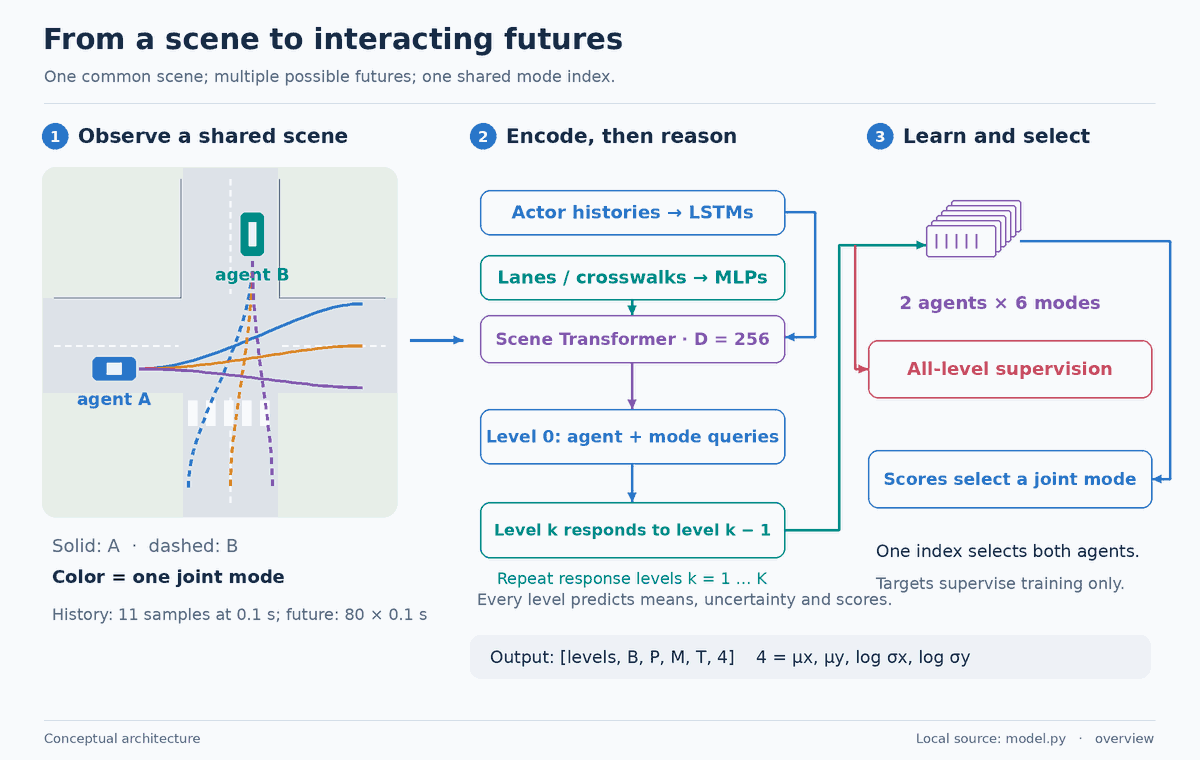

*One common scene; multiple possible futures; one shared mode index.*

## Setup

Requires Python >=3.11, PyTorch, NumPy and Matplotlib. Default execution is seeded, offline, on CPU. The full release uses D256, E6, K3, C34, P2, M6, H11 and T80. We retain T80 for the actual objective but reduce width, depth and context for the probes.

In [ ]:
import math
from dataclasses import dataclass
from typing import cast

import matplotlib.pyplot as plt
import torch
from torch import Tensor, nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.manual_seed(3407)
print("CPU:", torch.__version__)

In [ ]:
@dataclass(frozen=True)
class ModelConfig:
    width: int = 256
    heads: int = 8
    encoder_layers: int = 6
    levels: int = 3
    modes: int = 6
    actors: int = 34
    predicted: int = 2
    history: int = 11
    future: int = 80
    lanes: int = 6
    lane_points: int = 100
    crosswalks: int = 4
    crosswalk_points: int = 50
    lane_stride: int = 10
    crosswalk_stride: int = 10
    dropout: float = 0.1
    partial_segments: bool = False
    legacy_lane_columns: bool = True
    legacy_heading: bool = True
    normalized_future_pool: bool = False

    def __post_init__(self) -> None:
        integers = (
            self.width,
            self.heads,
            self.encoder_layers,
            self.modes,
            self.actors,
            self.predicted,
            self.history,
            self.future,
            self.lanes,
            self.lane_points,
            self.crosswalks,
            self.crosswalk_points,
            self.lane_stride,
            self.crosswalk_stride,
        )
        if any(x < 1 for x in integers) or self.levels < 0:
            raise ValueError("Model dimensions must be positive; levels may be zero")
        if self.width % self.heads or self.width % 2 or self.predicted > self.actors:
            raise ValueError("Width must be even/divisible by heads; predicted <= actors")
        if self.lane_points % self.lane_stride or self.crosswalk_points % self.crosswalk_stride:
            raise ValueError("Map point counts must be divisible by segment strides")
        if not 0 <= self.dropout < 1:
            raise ValueError("Dropout must be in [0,1)")

    @classmethod
    def smoke(cls) -> "ModelConfig":
        return cls(
            width=32,
            heads=4,
            encoder_layers=1,
            levels=1,
            actors=4,
            lanes=2,
            lane_points=20,
            crosswalks=1,
            crosswalk_points=10,
            dropout=0,
        )

## Data, coordinates and explicit masks

$p_{local}=R(-\theta_0)(p_{world}-p_0)$; positions are meters and angles radians. The first target defines the origin and need not be the autonomous vehicle. `actor_valid`, `lane_valid`, `crosswalk_valid` and `future_valid` distinguish missing data from legitimate zero coordinates. Future labels are excluded from model inputs. A scene contains observations [C,H,9], lane points [P,L,Q,17], crosswalks [P,W,R,3] and targets [P,T,2].

### Read the scene before reading its tensors

Choose the first target's current position and heading as the coordinate frame.
Translate every position by that origin, then rotate so local +x points forward
and +y points left. In the worked scene, the origin is `(10,5)` m and its heading
is 90 degrees. A world point `(10,6)` has displacement `(0,1)`; rotating by -90
degrees gives local `(1,0)` m. The same physical point now has a convenient
forward-distance interpretation. All agents and both targets' map selections
use this common frame; *agent-local map context* means a selection around each
agent, not a separate rotation of its coordinates.

Each history row contains `x,y,heading,vx,vy,length,width,height,type_id`.
H=11 includes the current sample; the T=80 labels cover 0.1 through 8 seconds
ahead. The target axis P is distinct from the larger observed-actor axis C.
Validity is an independent Boolean axis: `(0,0)` can be a real current position,
whereas an invalid row is excluded even if its stored numbers look plausible.
The probe deliberately keeps the focal actor at the valid origin and prints all
batch shapes. This checks the input contract; synthetic geometry does not
establish parity with real-data preprocessing.

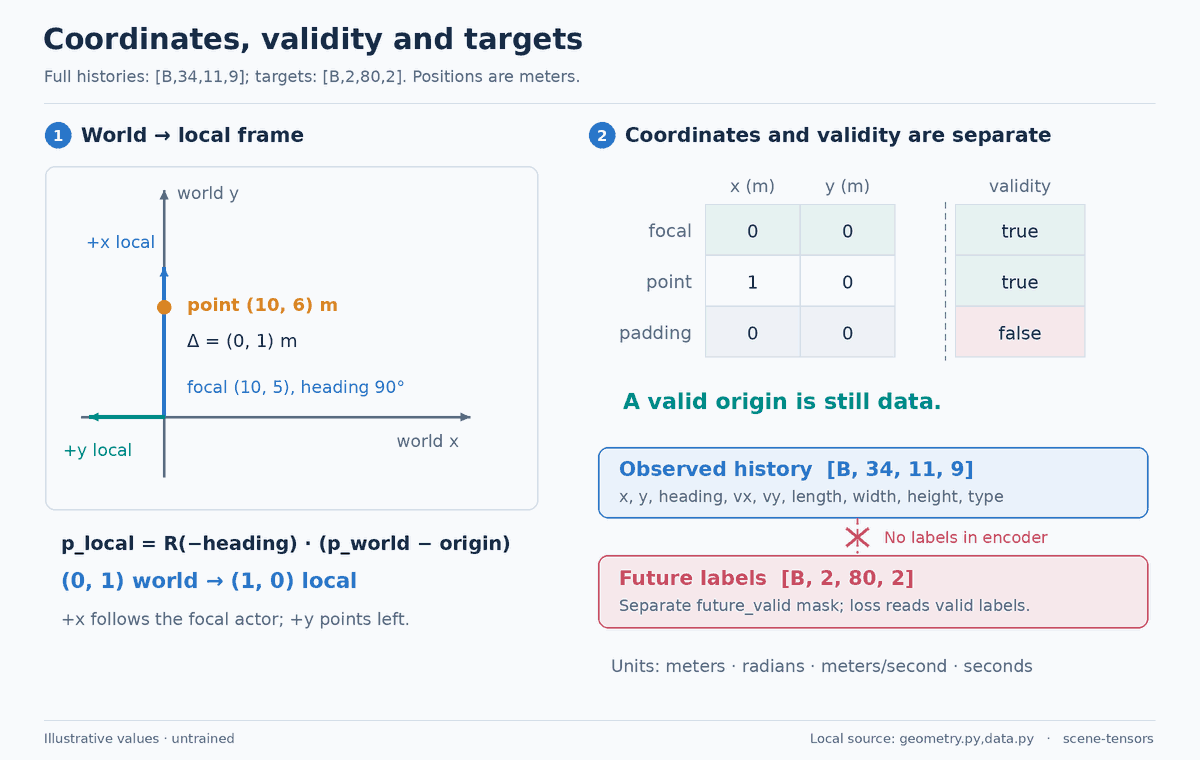

*Full histories: [B,34,11,9]; targets: [B,2,80,2]. Positions are meters.*

In [ ]:
def world_to_local(xy: Tensor, origin: Tensor, heading: Tensor) -> Tensor:
    while origin.ndim < xy.ndim:
        origin = origin.unsqueeze(-2)
    while heading.ndim < xy.ndim - 1:
        heading = heading.unsqueeze(-1)
    delta = xy - origin
    c, s = heading.cos(), heading.sin()
    return torch.stack(
        (c * delta[..., 0] + s * delta[..., 1], -s * delta[..., 0] + c * delta[..., 1]), -1
    )


def local_to_world(xy: Tensor, origin: Tensor, heading: Tensor) -> Tensor:
    while origin.ndim < xy.ndim:
        origin = origin.unsqueeze(-2)
    return world_to_local(xy, torch.zeros_like(origin), -heading) + origin


def wrap_angle(angle: Tensor) -> Tensor:
    return torch.atan2(angle.sin(), angle.cos())


def shapes(c: ModelConfig) -> dict[str, tuple[int, ...]]:
    return {
        "ego_state": (c.history, 9),
        "neighbors_state": (c.actors - 1, c.history, 9),
        "actor_valid": (c.actors, c.history),
        "map_lanes": (c.predicted, c.lanes, c.lane_points, 17),
        "lane_valid": (c.predicted, c.lanes, c.lane_points),
        "map_crosswalks": (c.predicted, c.crosswalks, c.crosswalk_points, 3),
        "crosswalk_valid": (c.predicted, c.crosswalks, c.crosswalk_points),
        "future": (c.predicted, c.future, 2),
        "future_state": (c.predicted, c.future, 5),
        "future_valid": (c.predicted, c.future),
    }


def validate_sample(sample: dict[str, Tensor], config: ModelConfig) -> None:
    for name, shape in shapes(config).items():
        if name not in sample or tuple(sample[name].shape) != shape:
            raise ValueError(f"{name}: expected {shape}; explicit masks and future_state required")
        if name.endswith("valid") and sample[name].dtype != torch.bool:
            raise ValueError(f"{name} must be boolean")
    actors = torch.cat((sample["ego_state"][None], sample["neighbors_state"]))
    for values, valid in (
        (actors, sample["actor_valid"]),
        (sample["map_lanes"], sample["lane_valid"]),
        (sample["map_crosswalks"], sample["crosswalk_valid"]),
        (sample["future_state"], sample["future_valid"]),
        (sample["future"], sample["future_valid"]),
    ):
        if not torch.isfinite(values[valid]).all():
            raise ValueError("Non-finite value in a valid scene entry")
    if not sample["actor_valid"][0, -1]:
        raise ValueError("Focal actor must be valid at the current time")
    ids = actors[..., 8][sample["actor_valid"]]
    if ((ids < 0) | (ids > 3) | (ids != ids.round())).any():
        raise ValueError("Agent type IDs must be integers in [0,3]")


def synthetic_sample(c: ModelConfig, index: int, seed: int = 3407) -> dict[str, Tensor]:
    """Illustrative constant-velocity scenes; this is not a WOMD sample."""
    g = torch.Generator().manual_seed(seed + index)
    actors = torch.zeros(c.actors, c.history, 9)
    positions = torch.randn(c.actors, 2, generator=g) * 4
    positions[0] = 0
    velocity = torch.randn(c.actors, 2, generator=g) * 0.2
    velocity[:, 0] += 2
    times = torch.arange(1 - c.history, 1) * 0.1
    actors[..., :2] = positions[:, None] + velocity[:, None] * times[None, :, None]
    actors[..., 2] = torch.atan2(velocity[:, 1], velocity[:, 0])[:, None]
    actors[..., 3:5] = velocity[:, None]
    actors[..., 5:8] = torch.tensor([4.0, 2.0, 1.5])
    actors[..., 8] = torch.arange(c.actors).remainder(3)[:, None] + 1
    lanes = torch.zeros(c.predicted, c.lanes, c.lane_points, 17)
    x = torch.linspace(-5, 40, c.lane_points)
    for lane in range(c.lanes):
        for offset, y in ((0, lane * 3.0), (3, lane * 3.0 + 1.5), (6, lane * 3.0 - 1.5)):
            lanes[:, lane, :, offset] = x
            lanes[:, lane, :, offset + 1] = y
    lanes[..., 9] = 13.4
    lanes[..., 10:13] = 1
    crosswalks = torch.randn(c.predicted, c.crosswalks, c.crosswalk_points, 3, generator=g)
    future_times = torch.arange(1, c.future + 1) * 0.1
    future = (
        positions[: c.predicted, None] + velocity[: c.predicted, None] * future_times[None, :, None]
    )
    state = torch.cat((future, actors[: c.predicted, -1, None, 2:5].expand(-1, c.future, -1)), -1)
    sample = {
        "ego_state": actors[0],
        "neighbors_state": actors[1:],
        "actor_valid": torch.ones(c.actors, c.history, dtype=torch.bool),
        "map_lanes": lanes,
        "lane_valid": torch.ones(lanes.shape[:-1], dtype=torch.bool),
        "map_crosswalks": crosswalks,
        "crosswalk_valid": torch.ones(crosswalks.shape[:-1], dtype=torch.bool),
        "future": future,
        "future_state": state,
        "future_valid": torch.ones(c.predicted, c.future, dtype=torch.bool),
    }
    validate_sample(sample, c)
    return sample

In [ ]:
config = ModelConfig.smoke()
samples = [synthetic_sample(config, i, 3407) for i in range(2)]
batch = {key: torch.stack([s[key] for s in samples]) for key in samples[0]}
assert batch["actor_valid"][0, 0, -1]
assert torch.equal(batch["ego_state"][0, -1, :2], torch.zeros(2))
print({key: tuple(value.shape) for key, value in batch.items()})

## Actor history

An LSTM updates memory as $c_t=f_t c_{t-1}+i_t g_t$ and $h_t=o_t\tanh(c_t)$. Two layers encode eight numeric fields; the last hidden state receives a categorical type embedding. Separate weights encode the focal actor and all remaining actors. Invalid history rows are zeroed before encoding; the current validity controls the actor attention mask.

### A token carries motion history, not one raw observation

Trace the history sequence into one actor token. An LSTM is a recurrent network
with a *cell state*, its running memory. Its gates are learned numbers that
control how much old memory to retain, how much candidate memory to add and how
much to expose. For one illustrative channel, old memory 1.0, forget gate 0.8,
input gate 0.5 and candidate 0.4 produce
$c_{new}=0.8\cdot1+0.5\cdot0.4=1$. With output gate 0.5,
$h_{new}=0.5\tanh(1)\approx0.3808$. Adding a toy type embedding 0.1 gives 0.4808.
The actual gates operate on D channels with learned matrices.

The numeric path is `[B,H,8] -> [B,H,D] -> [B,D]`; the ninth field selects a
categorical type embedding added to the last output. Two stacked recurrent
layers learn progressively transformed history. Focal and other actors have
separate encoders, while all non-focal actors share one encoder's weights.
Invalid history rows are zeroed by `GameFormer` before this component runs;
zero rows still pass through the recurrence rather than being skipped. Current
validity later controls visibility in attention. The probe checks the final
token width; its random initialization does not reproduce the hand-set gates.

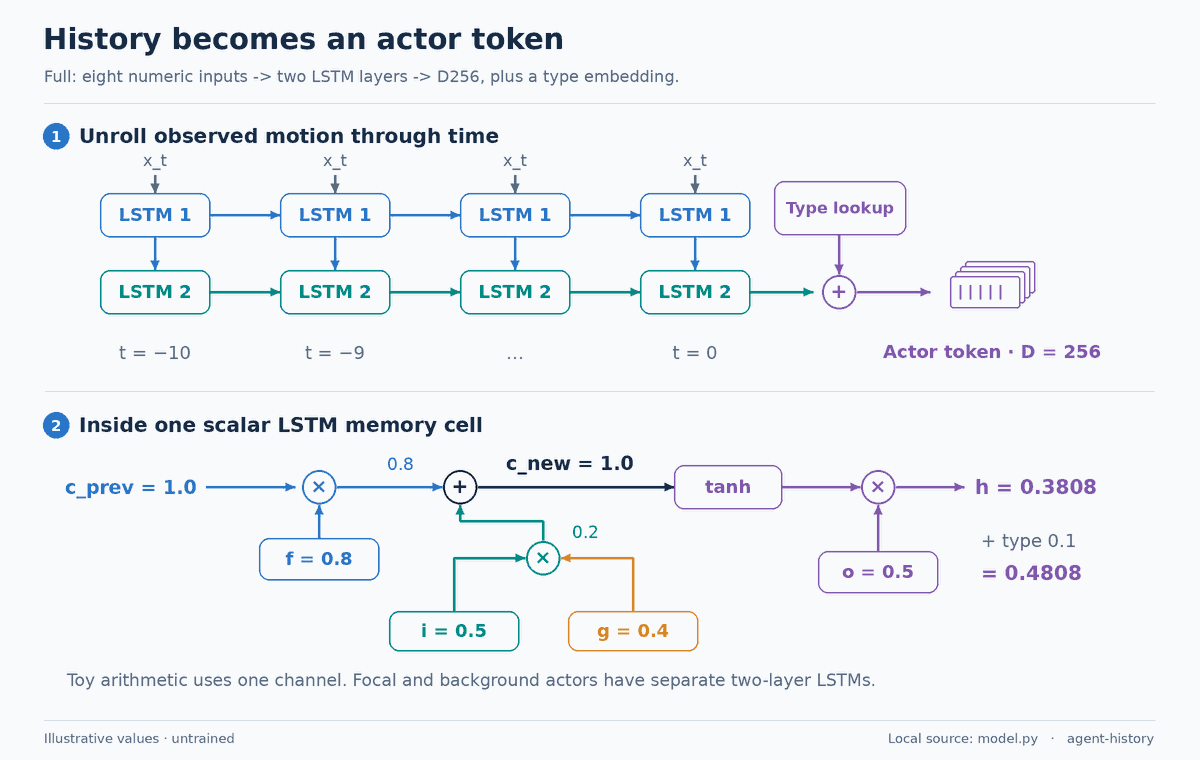

*Full: eight numeric inputs -> two LSTM layers -> D256, plus a type embedding.*

In [ ]:
class AgentEncoder(nn.Module):
    def __init__(self, width: int):
        super().__init__()
        self.motion = nn.LSTM(8, width, 2, batch_first=True)
        self.type_emb = nn.Embedding(4, width, padding_idx=0)

    def forward(self, states: Tensor) -> Tensor:
        encoded, _ = self.motion(states[..., :8])
        return encoded[:, -1] + self.type_emb(states[:, -1, 8].long())

In [ ]:
actor_encoder = AgentEncoder(config.width)
assert actor_encoder(batch["ego_state"]).shape == (2, config.width)

## Lane points

Numeric boundary coordinates use linear projections; discrete IDs use embeddings. Concatenate three 128-channel geometry features, 64 speed channels and 64 summed semantic channels; apply a 512→384→D MLP, then sinusoidal point positions $PE_{p,2j}=\sin(p/10000^{2j/D})$. The source has a lane-column disagreement: compatibility uses 14/15, whereas corrected semantics use 15/16. The configuration names this choice.

### Geometry and road rules enter through different paths

Read a lane point as several kinds of information. Centerline, left boundary
and right boundary each supply `(x,y,heading)` to a separate linear projection.
Speed is a continuous number with its own projection. Lane type, boundary type,
signal and binary attributes instead select learned vectors from embedding
tables: an ID names a category, so category 2 need not mean twice category 1.
The six semantic vectors are **summed**, giving 64 channels together. They are
then concatenated with `3*128` geometry channels and 64 speed channels:
$384+64+64=512$. The point network maps 512 to 384 to D.

The point index also matters. Adding sinusoidal position features lets two
otherwise similar points carry different positions along the lane. At point
index zero, a toy sine/cosine pair is `(0,1)`, so a learned feature `(0.5,0.6)`
becomes `(0.5,1.6)` before dropout. This is an example slice, not a measured
lane embedding. The full tensor retains `[B,P,6,100,D]` until segment pooling.
Compatibility intentionally reads semantic columns 14/15 where preprocessing
describes different fields; corrected 15/16 columns are a named configuration
choice. The probe verifies D channels without claiming those two recipes agree.

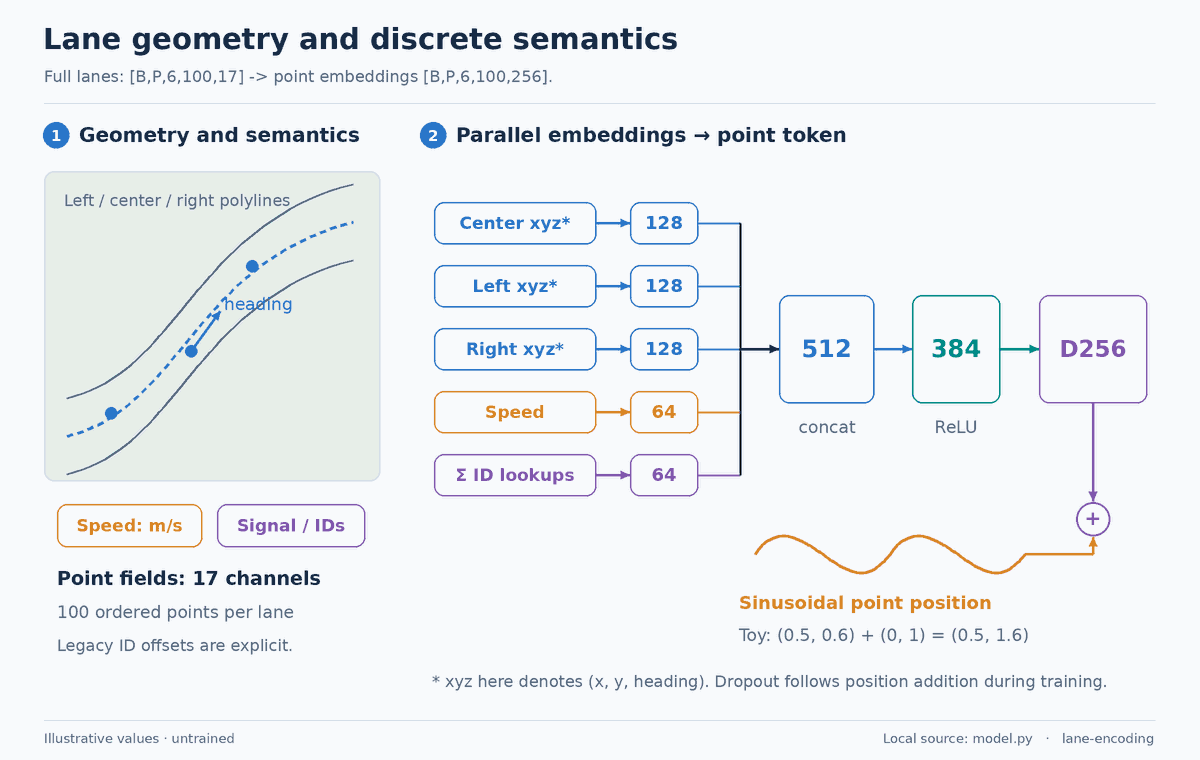

*Full lanes: [B,P,6,100,17] -> point embeddings [B,P,6,100,256].*

In [ ]:
class PositionalEncoding(nn.Module):
    pe: Tensor

    def __init__(self, width: int, length: int, dropout: float):
        super().__init__()
        positions = torch.arange(length)[:, None]
        divisor = torch.exp(torch.arange(0, width, 2) * (-math.log(10000.0) / width))
        pe = torch.zeros(length, width)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(positions * divisor), torch.cos(positions * divisor)
        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: Tensor) -> Tensor:
        return self.dropout(x + self.pe)


class LaneEncoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.lines = nn.ModuleList([nn.Linear(3, 128) for _ in range(3)])
        self.speed = nn.Linear(1, 64)
        self.attributes = nn.ModuleList(
            [
                nn.Embedding(n, 64, padding_idx=0 if i < 4 else None)
                for i, n in enumerate((4, 11, 11, 9, 2, 2))
            ]
        )
        self.pointnet = nn.Sequential(nn.Linear(512, 384), nn.ReLU(), nn.Linear(384, c.width))
        self.position = PositionalEncoding(c.width, c.lane_points, c.dropout)
        self.columns = (
            (10, 11, 12, 13, 14, 15) if c.legacy_lane_columns else (10, 11, 12, 13, 15, 16)
        )

    def forward(self, lanes: Tensor) -> Tensor:
        numeric = [layer(lanes[..., i * 3 : i * 3 + 3]) for i, layer in enumerate(self.lines)]
        semantic = sum(
            layer(lanes[..., col].long())
            for col, layer in zip(self.columns, self.attributes, strict=True)
        )
        return self.position(
            self.pointnet(torch.cat([*numeric, self.speed(lanes[..., 9:10]), semantic], -1))
        )

In [ ]:
lane_encoder = LaneEncoder(config)
assert lane_encoder(batch["map_lanes"]).shape[-1] == config.width

## Crosswalk points

A local MLP maps three numeric fields (x,y,heading) through 64, 128 and D channels with ReLU activations. It preserves every point until pooling. No external map encoder or model library is used.

### Keep every point until the reduction step

The crosswalk branch starts from `(x,y,heading)` and applies the same small
feature network independently to every point. A *linear layer* computes a
weighted sum plus a bias; ReLU keeps positive values and replaces negative
values by zero. In the illustrative first layer, rows `(1,0,0)` and `(0,-1,0)`
with zero biases transform point `(2,-1,0)` to `(2,1)`. ReLU leaves `(2,1)`
unchanged. The real network uses widths `3 -> 64 -> 128 -> D`, with ReLU after
the first two projections, rather than the two-channel toy output.

Nothing has yet averaged all crosswalk geometry into one number. The full
released tensor is `[B,P,4,50,D]`: four selected crosswalks, fifty points each,
for each predicted actor's map selection. Unlike lanes, this branch adds no
sinusoidal point-position features. Nevertheless, downstream groups still use
the point order supplied by preprocessing. Padding coordinates are zeroed
before encoding, but biased layers can give zero inputs nonzero features;
therefore the separate validity mask remains essential at pooling. The probe
checks that the final channel width is D. The next section explains exactly
which point values survive into scene attention.

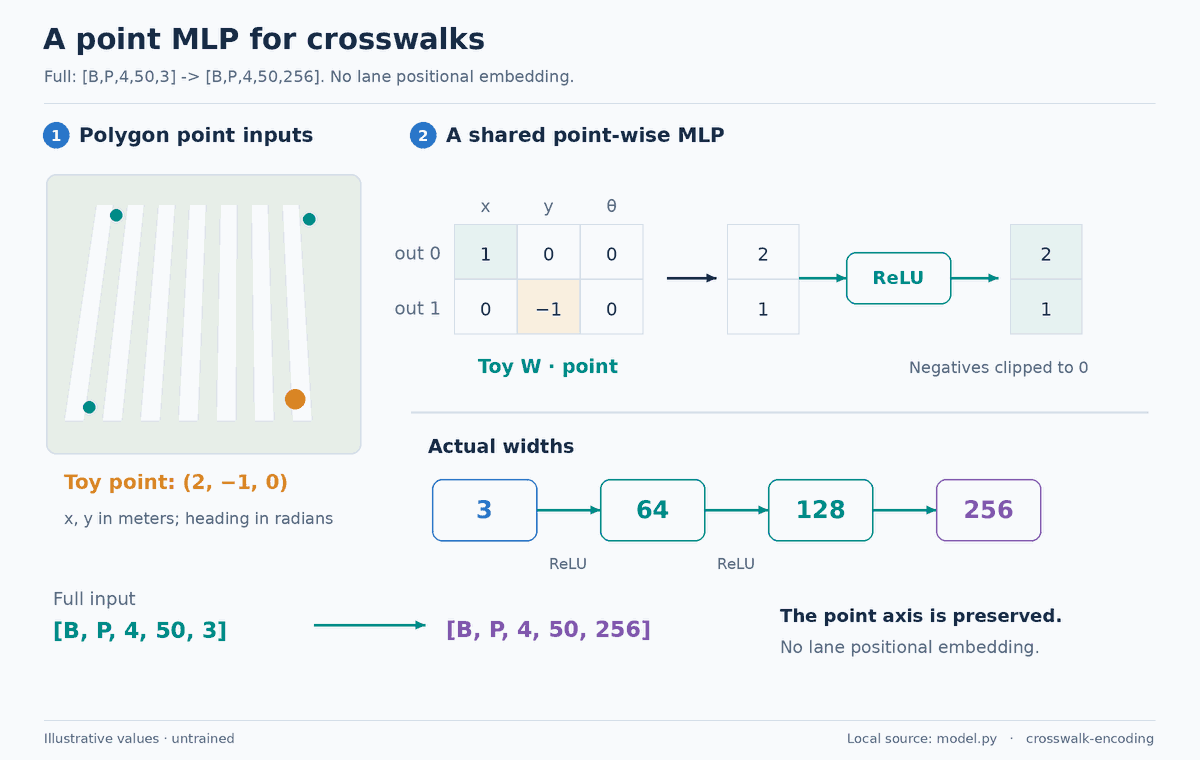

*Full: [B,P,4,50,3] -> [B,P,4,50,256]. No lane positional embedding.*

In [ ]:
class CrosswalkEncoder(nn.Module):
    def __init__(self, width: int):
        super().__init__()
        self.pointnet = nn.Sequential(
            nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, width)
        )

    def forward(self, points: Tensor) -> Tensor:
        return self.pointnet(points)

In [ ]:
crosswalk_encoder = CrosswalkEncoder(config.width)
assert crosswalk_encoder(batch["map_crosswalks"]).shape[-1] == config.width

## Reduce map tokens

$z_{segment,d}=\max_{q\in valid} z_{q,d}$. Different channels can select different points. Every pooled token retains a padding flag (True means hidden). The released policy hides a partly invalid segment; the practical policy admits any valid point. Entirely empty groups produce zero features and remain hidden.

### A pooled token can borrow channels from different points

Max pooling reduces the map's point count while preserving a strong response
in each feature channel. First group consecutive points, then replace invalid
features by negative infinity, then take a maximum **separately per channel**.
For valid features `(1,4)` and `(7,2)`, the result is `(7,4)`: its first channel
comes from the second point and its second channel from the first. A padded
`(99,99)` must contribute neither value. The result is a learned feature vector,
not a new physical point at coordinate `(7,4)`.

Released lane grouping makes `6*(100/10)=60` tokens per target; crosswalk
grouping makes `4*(50/10)=20`. With C=34 actor tokens this gives S=114 scene
tokens. Here S names the scene-token axis, not a time axis.

The two policies separate numeric reduction from token visibility. Compatibility
requires every point in a group valid; the practical partial policy requires
at least one. An entirely empty group receives a finite zero vector and stays
hidden in either policy. The upcoming probe explicitly enables the partial
policy and verifies `(7,4)` despite the invalid large values. It does not assert
that the same partly valid group is visible under the default strict policy.

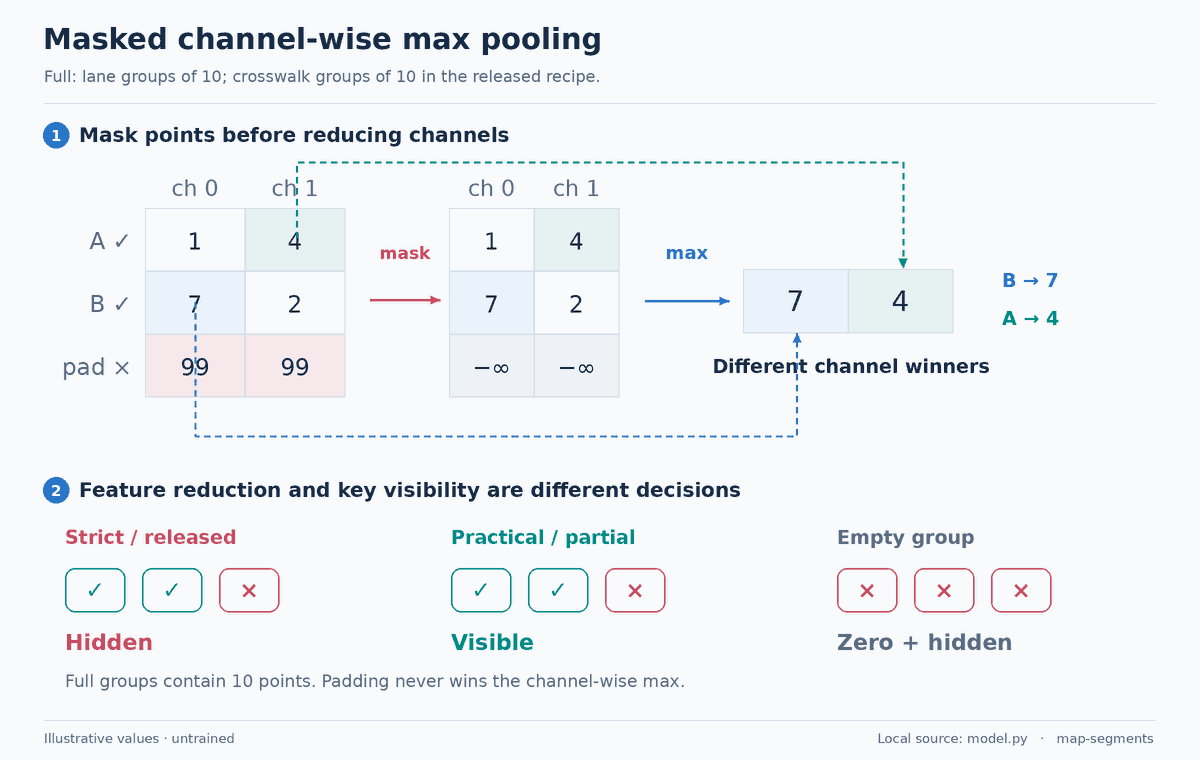

*Full: lane groups of 10; crosswalk groups of 10 in the released recipe.*

In [ ]:
def segment_points(
    features: Tensor, valid: Tensor, stride: int, partial: bool = False
) -> tuple[Tensor, Tensor]:
    """[B,L,Q,D] -> [B,L*Q/stride,D], True padding mask; never pool padding."""
    b, lanes, points, width = features.shape
    grouped = features.reshape(b, lanes, points // stride, stride, width)
    flags = valid.reshape(b, lanes, points // stride, stride)
    pooled = grouped.masked_fill(~flags[..., None], -torch.inf).amax(-2)
    any_valid = flags.any(-1)
    pooled = torch.where(any_valid[..., None], pooled, 0)
    usable = any_valid if partial else flags.all(-1)
    return pooled.reshape(b, -1, width), ~usable.reshape(b, -1)

In [ ]:
toy = torch.tensor([[[[1.0, 4.0], [7.0, 2.0], [99.0, 99.0]]]])
pooled, padding = segment_points(toy, torch.tensor([[[True, True, False]]]), 3, True)
torch.testing.assert_close(pooled, torch.tensor([[[7.0, 4.0]]]))
assert not padding.any()

## Context and attention

$Attention(Q,K,V)=softmax(QK^T/\sqrt{d}+mask)V$. Concatenate actor tokens and the target agent’s local map. The scene Transformer uses post-normalization and residual connections. The released cross-attention block normalizes the read without adding the query, an important implementation detail. FFN means a two-layer feature network.

### Attention is a weighted read of visible tokens

Treat a query as a request and each key as a description of available content;
the corresponding value supplies the content to read. Dot products measure
query-key compatibility. Division by $\sqrt d$ controls score scale, and
softmax converts visible scores into nonnegative weights summing to one.
A padding mask hides a key before softmax. In the scalar example, values
`(2,4,99)` with weights `(.25,.75,0)` yield `0.25*2+0.75*4=3.5`; the masked
99 cannot contaminate the read. Learned attention usually has several heads,
each making a separate read of projected channels.

Each predicted agent receives all C actor tokens and its selected map tokens.
The implementation folds B and P into one batch axis, so scene input is
`[B*P,S,D]`. The Transformer preserves these axes while enriching each token
with context. Residual addition carries an input around a sublayer; layer
normalization rescales its channels. Scene and future self-attention use
residuals, but the released decoder cross-attention omits the query residual
around its attention read. Its feature-network residual remains. The probe
checks self-attention shape preservation; the illustrated weights are fixed
teaching values, not attention weights recovered from that random module.

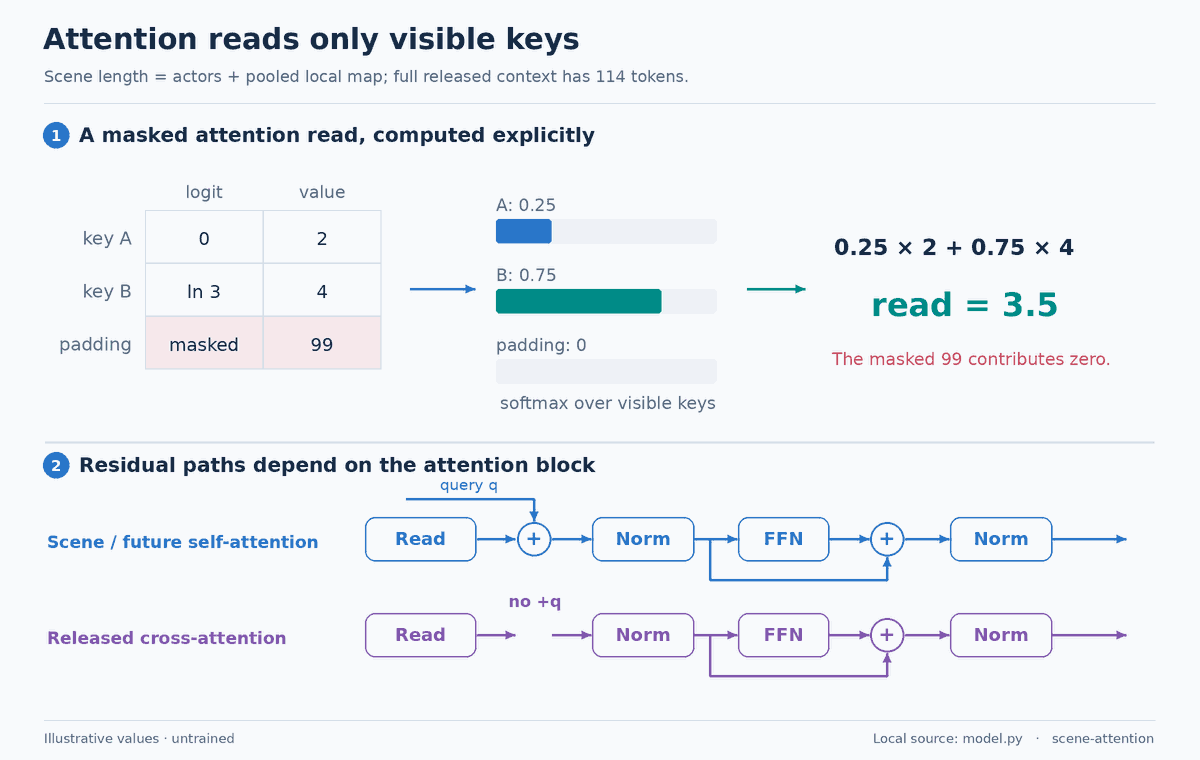

*Scene length = actors + pooled local map; full released context has 114 tokens.*

In [ ]:
class AttentionBlock(nn.Module):
    """Post-norm attention. Cross-attention has no query residual in the release."""

    def __init__(self, c: ModelConfig, self_attention: bool = False):
        super().__init__()
        self.attention = nn.MultiheadAttention(c.width, c.heads, c.dropout, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(c.width), nn.LayerNorm(c.width)
        self.ffn = nn.Sequential(
            nn.Linear(c.width, c.width * 4),
            nn.GELU(),
            nn.Dropout(c.dropout),
            nn.Linear(c.width * 4, c.width),
            nn.Dropout(c.dropout),
        )
        self.self_attention = self_attention

    def forward(self, query: Tensor, context: Tensor, mask: Tensor) -> Tensor:
        attended = self.attention(
            query, context, context, key_padding_mask=mask, need_weights=False
        )[0]
        attended = self.norm1(attended + query if self.self_attention else attended)
        return self.norm2(attended + self.ffn(attended))

In [ ]:
attention = AttentionBlock(config, self_attention=True)
tokens = torch.randn(2, 3, config.width)
assert attention(tokens, tokens, torch.zeros(2, 3, dtype=torch.bool)).shape == tokens.shape

## Level-0 queries

$q_{i,m}=context_i+embedding_{agent,i}+embedding_{mode,m}$. Each agent and mode gets a distinct query, which reads the common scene through cross-attention. No previous future is available at this stage.

### Ask several different questions of the same observed scene

After scene encoding, choose each predicted actor's contextualized actor token.
Add one learned vector identifying the actor and another identifying the mode.
An *embedding* is simply a trainable vector indexed by an ID. Element-wise
addition preserves D channels: toy vectors `(1,2)`, `(.5,0)` and `(0,-.5)`
produce query `(1.5,1.5)`. The model broadcasts these ingredients over
`[B,P,M,D]`, forming twelve queries per scene in the released P2, M6 case.
Each query then reads its target's observed context through cross-attention.

Mode IDs provide consistent slots for alternative joint futures, without
hard-coding meanings such as “turn left” or “yield.” Both agents' mode m forms
one joint alternative; independently pairing agent A's mode 0 with agent B's
mode 4 would break that interpretation. At this initial level, no predicted
future is available to condition the read. There is also no self-attention
between the M query slots in this block: diversity comes from their distinct
embeddings and learned predictions, with interaction introduced later.
The following probe verifies the addition arithmetic only. The complete
assembly probe will exercise the learned embeddings and scene read together.

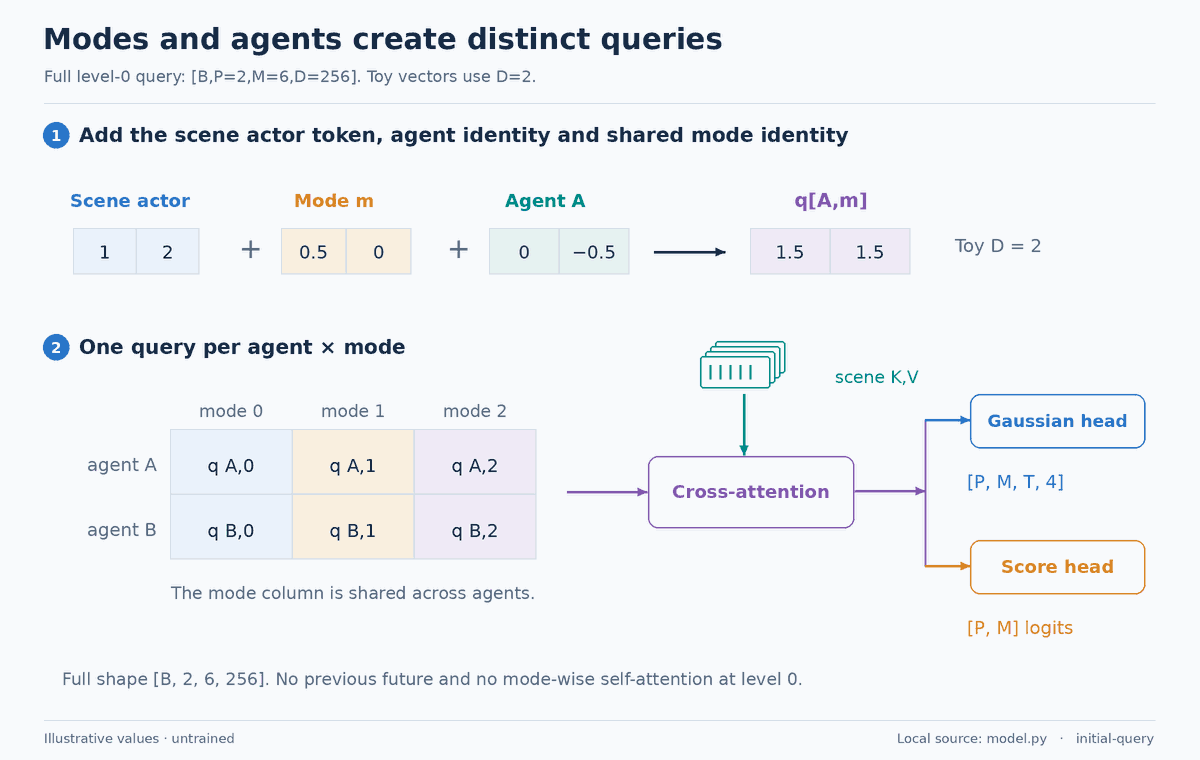

*Full level-0 query: [B,P=2,M=6,D=256]. Toy vectors use D=2.*

In [ ]:
query = torch.tensor([1.0, 2.0]) + torch.tensor([0.5, 0.0]) + torch.tensor([0.0, -0.5])
torch.testing.assert_close(query, torch.tensor([1.5, 1.5]))

## Decode Gaussian components

A Gaussian mixture represents alternative possible futures. Each mode has a mean (x,y), diagonal log standard deviations, and a score. The head emits offsets from the current position, rather than per-step increments. $\mu_t=p_{current}+\Delta p_t$ and $\sigma_t=\exp(log\sigma_t)$.

### Separate where a future goes, its spread and its score

For every agent-mode query, one head emits T sets of four numbers and another
emits one scalar score. Read a row as
`mu_x,mu_y,log_sigma_x,log_sigma_y`. The mean is a position; the standard
deviation sigma describes spread around it along an axis. A log standard
deviation of zero means sigma=1, while $\log 2$ means sigma=2. These are not
variances: the corresponding variances would be 1 and 4. The diagonal model
has no learned x-y covariance term and no explicit cross-time covariance.

Suppose the current position is `(10,2)` m and one predicted offset is `(3,1)`
m. The mean is `(13,3)` m. Every timestep is anchored directly to the **same
current position**; the head does not integrate a chain of incremental moves.
This matters when comparing its outputs to the later finite-difference
velocity calculation. The scalar score belongs to the entire mode trajectory,
not each future step; softmax turns the M scores into relative mode weights.

The probe checks `[2,2,6,80,4]` Gaussian parameters and `[2,2,6]` scores.
Despite its variable name `means`, that first returned tensor includes all
four Gaussian fields. Uncertainty is decoded here and clamped for the loss later.

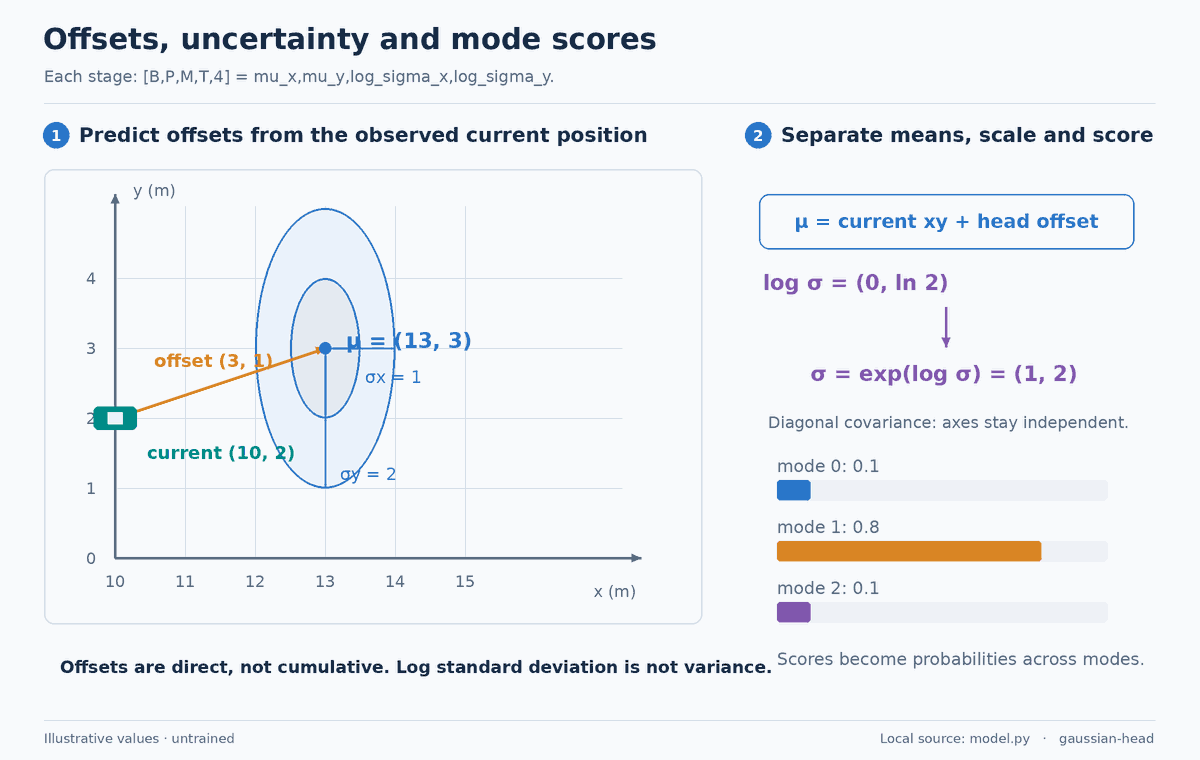

*Each stage: [B,P,M,T,4] = mu_x,mu_y,log_sigma_x,log_sigma_y.*

In [ ]:
class GaussianHead(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.future = c.future
        self.gaussian = nn.Sequential(
            nn.Linear(c.width, c.width * 2),
            nn.ELU(),
            nn.Dropout(c.dropout),
            nn.Linear(c.width * 2, c.future * 4),
        )
        self.score = nn.Sequential(
            nn.Linear(c.width, 64), nn.ELU(), nn.Dropout(c.dropout), nn.Linear(64, 1)
        )

    def forward(self, content: Tensor, current: Tensor) -> tuple[Tensor, Tensor]:
        raw = self.gaussian(content).reshape(*content.shape[:-1], self.future, 4)
        result = torch.cat((raw[..., :2] + current[:, :, None, None, :2], raw[..., 2:]), -1)
        return result, self.score(content).squeeze(-1)

In [ ]:
head = GaussianHead(config)
means, scores = head(torch.randn(2, 2, 6, config.width), torch.zeros(2, 2, 9))
assert means.shape == (2, 2, 6, 80, 4) and scores.shape == (2, 2, 6)

## Future kinematics and a gradient barrier

$v_t=(p_t-p_{t-1})/0.1$. Append heading and box dimensions to form eight channels. A shared MLP and time maximum encode every candidate future. The input kinematics are detached: this path cannot change previous xy through backpropagation. The future MLP, prior query content and score paths still learn. The legacy positive-dx clamp is explicit in configuration.

### Convert positions to motion features, then stop one gradient route

Follow a predicted xy trajectory into the next reasoning level. Prepend the
observed current position before taking differences, so the first velocity
has the same physical meaning as later ones. Moving from `(0,0)` to `(1,0)`
m over 0.1 seconds gives `(10,0)` m/s and heading zero. Concatenate position
(2 channels), heading (1), velocity (2) and observed length/width/height (3):
eight channels per step. A shared `8 -> 64 -> D` network encodes them; a
maximum over T removes time, producing `[B,P,M,D]`, then type is added.

The *gradient barrier* is `states.detach()`: later loss cannot change earlier
xy **through this kinematic-feature route**. The MLP still gets parameter
gradients, and earlier content and mode scores have other routes into later
levels. Earlier predictions also have their own direct supervision. Detach
does not freeze the entire earlier decoder.

Compatibility clamps delta-x to at least .001 for heading only. For a backward
move, that differs from geometric `atan2(dy,dx)`; velocity still uses the
original difference. The probe isolates this feature route: `xy.grad` stays
absent while the future MLP's weight gradient exists. It does not test all
possible gradient routes in the assembled network.

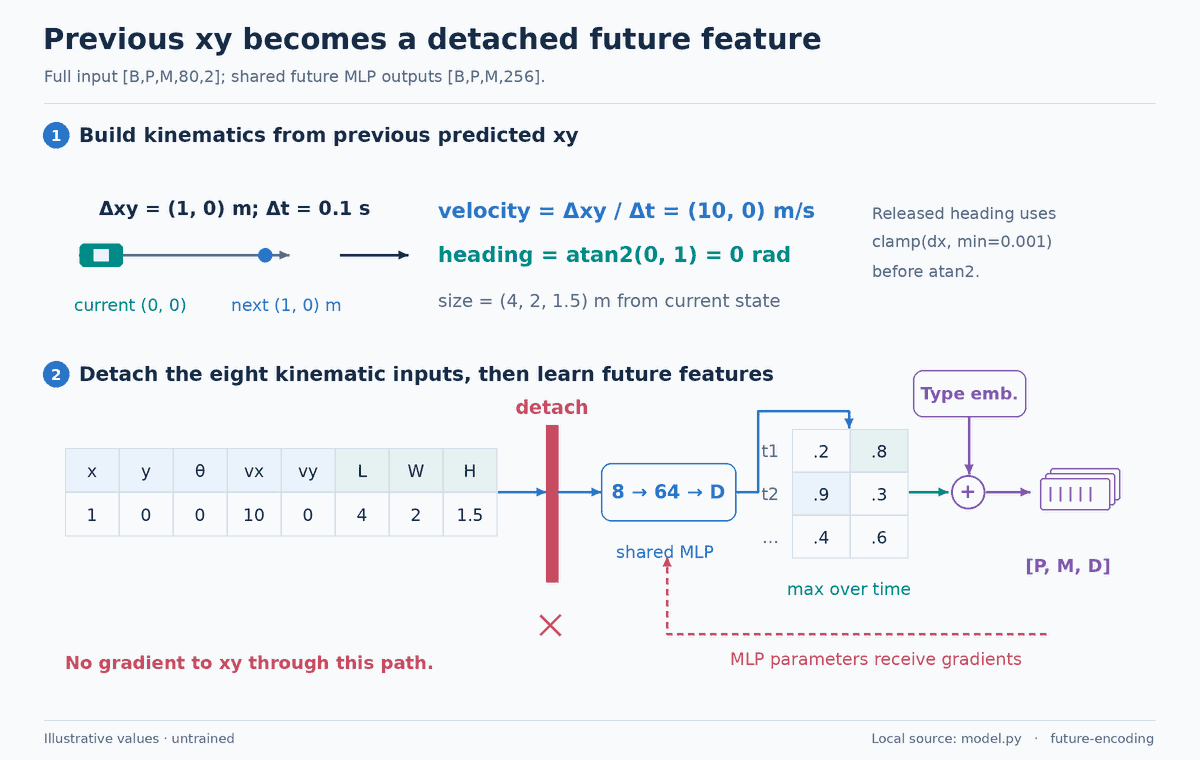

*Full input [B,P,M,80,2]; shared future MLP outputs [B,P,M,256].*

In [ ]:
class FutureEncoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(8, 64), nn.ReLU(), nn.Linear(64, c.width))
        self.type_emb = nn.Embedding(4, c.width, padding_idx=0)
        self.legacy_heading = c.legacy_heading

    def forward(self, trajectories: Tensor, current: Tensor) -> Tensor:
        # B,P,M,T,2; append the observed current xy before finite differences.
        start = current[:, :, None, None, :2].expand(-1, -1, trajectories.shape[2], -1, -1)
        delta = torch.diff(torch.cat((start, trajectories), -2), dim=-2)
        dx = delta[..., 0].clamp_min(1e-3) if self.legacy_heading else delta[..., 0]
        angle = torch.atan2(delta[..., 1], dx)[..., None]
        size = current[:, :, None, None, 5:8].expand(*trajectories.shape[:-1], 3)
        states = torch.cat((trajectories, angle, delta / 0.1, size), -1)
        features = self.mlp(states.detach()).amax(-2)
        return features + self.type_emb(current[:, :, None, 8].long())

In [ ]:
future_encoder = FutureEncoder(config)
xy = torch.randn(2, 2, 6, 80, 2, requires_grad=True)
encoded = future_encoder(xy, torch.zeros(2, 2, 9))
encoded.sum().backward()
assert xy.grad is None
assert future_encoder.mlp[0].weight.grad is not None

## Probability pooling and future interaction

The release computes $f_i=\frac1M\sum_m softmax(s_i)_m e_{i,m}$. This has an additional 1/M compared with a normalized expectation. Preserve it for compatibility. Self-attention mixes agents’ future tokens; each interaction level owns its attention and Gaussian head, while the future-feature MLP is shared across levels.

### Compress alternatives before agents read one another

Keep two future representations distinct. The multi-future tensor
`e[B,P,M,D]` retains every candidate mode. A second tensor pools those modes
into one token per agent, so future self-attention can compare agents on
`[B,P,D]`. With toy scalar features `(2,4)` and probabilities `(.25,.75)`,
weighted features are `(.5,3)`. The released operator takes their **mean**,
giving 1.75. A normalized probability-weighted sum would give 3.5. In the full
M6 model, this extra factor is 1/6; it is a compatibility choice, not evidence
that the probabilities fail to sum to one.

Self-attention then allows each agent's pooled token to read other agents'
pooled tokens. Its outputs can contain information about several agents, so
they are mixed interaction features rather than isolated future descriptions.
The unpooled multi-future features remain available to modify each mode's next
query. One future MLP is shared across reasoning levels; each level has its
own interaction attention, cross-attention and prediction head. Shared weights
therefore do not imply identical behavior at every level.

The probe verifies the unusual 1.75 arithmetic and constructs an interaction
block. The later full-model call exercises attention across agents and checks
that all prediction stages are retained.

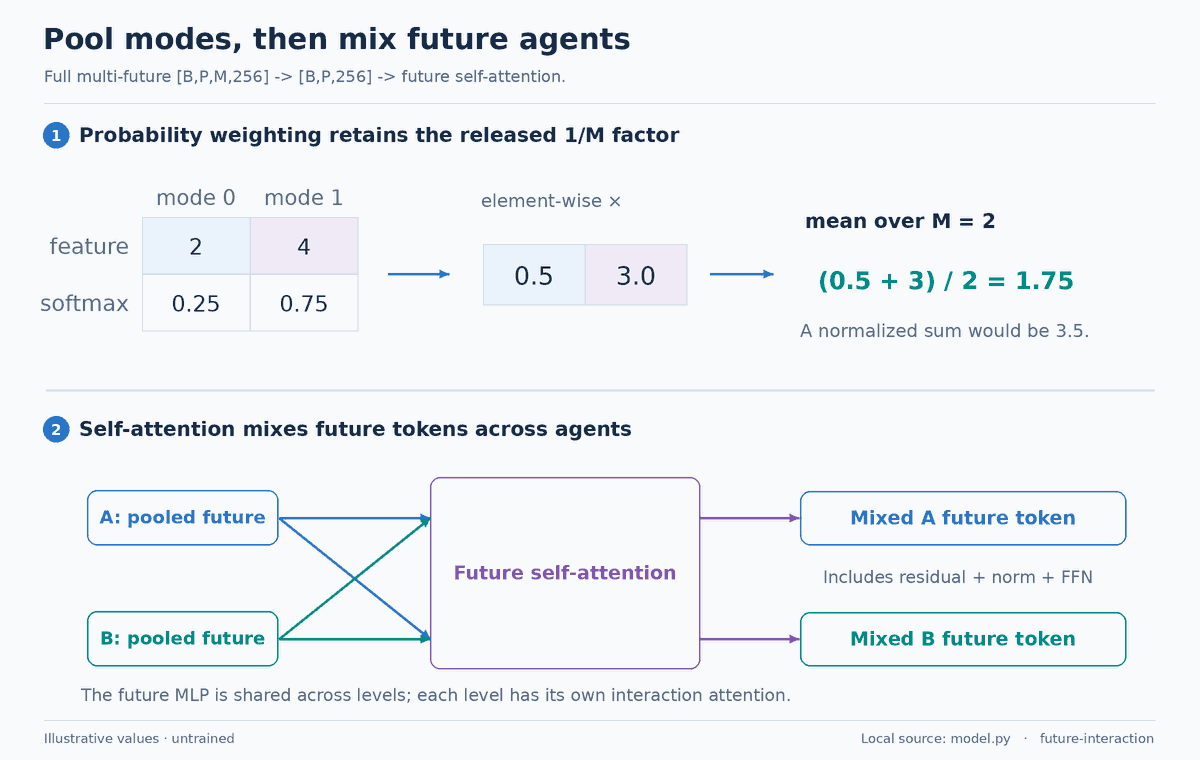

*Full multi-future [B,P,M,256] -> [B,P,256] -> future self-attention.*

In [ ]:
class InteractionDecoder(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.interaction = AttentionBlock(c, self_attention=True)
        self.cross = AttentionBlock(c)
        self.head = GaussianHead(c)

In [ ]:
toy_pool = (torch.tensor([2.0, 4.0]) * torch.tensor([0.25, 0.75])).mean()
assert toy_pool.item() == 1.75
interaction = InteractionDecoder(config)

## Level-k cross-attention

Append mixed future tokens to the original scene. Add the own multi-future embedding to prior query content, then read this extended context. Hide the own-future key after future self-attention, matching the release. This masking location does not establish complete causal isolation.

### Identify which connections the mask actually removes

At level k, each mode's next query is previous decoder content plus its own
unpooled future embedding. Its context includes mixed future-agent tokens and
the original encoded scene. For two predicted agents, the future-key mask is
`[[True,False],[False,True]]`: row A hides future token A and can read future
token B; row B does the reverse. True means **hidden**, the opposite of the
input validity masks where True means present. Absent actors and scene padding
also remain hidden.

This is not a rule saying an agent cannot use information about itself. Its
own multi-future embedding explicitly enters the query, and its observed actor
token remains in the scene. More subtly, future self-attention happened before
this mask: token B may already contain information read from A. Hiding the
token labelled A therefore removes a direct key-value read, without proving
that every indirect A-to-A information path is absent. Read the diagram's
arrows in that sequence before interpreting the crossed-out connection.

The next probe constructs the diagonal mask and verifies its Boolean values.
It demonstrates the intended direct visibility pattern; it does not measure
information isolation or establish a causal guarantee about learned features.

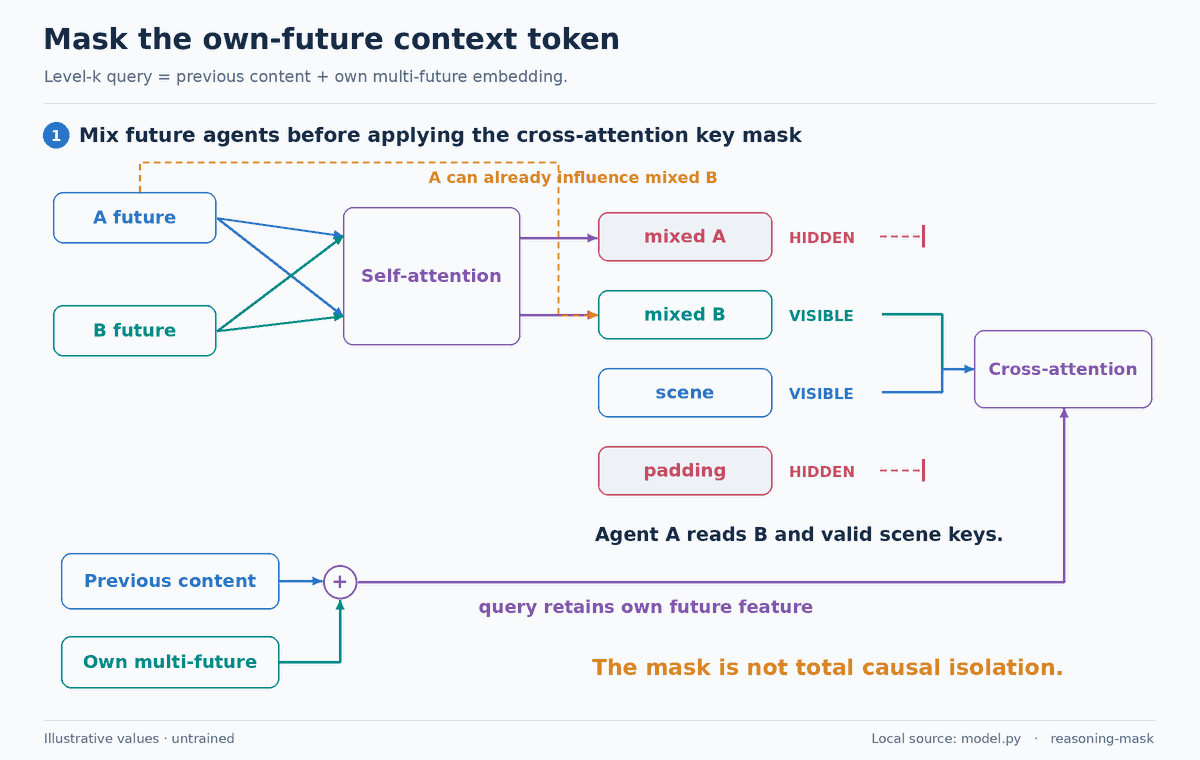

*Level-k query = previous content + own multi-future embedding.*

In [ ]:
own_future_hidden = torch.eye(config.predicted, dtype=torch.bool)
assert own_future_hidden.tolist() == [[True, False], [False, True]]

## Assemble the complete model

All observed actors appear in every agent-local context. Only the first P actors are decoded. For each level, predicted means and scores feed the next level, alongside previous query content. Retain all K+1 stages for deep supervision. Vectorized agent contexts match release operations in evaluation; training dropout draws need not follow upstream RNG order.

### Count stages and distinguish context from predictions

The assembly connects earlier components without replacing the observed scene
at every level. Encode histories and map segments once, then create one
context per predicted agent. All C actors appear in each context, while the
map selection differs by target. In the full recipe, `34+60+20=114` tokens
give scene shape `[B,2,114,256]`. Only the first P=2 actors are decoded; the
other 32 still provide useful observed traffic context.

Level 0 reads that scene. Each of the K interaction stages takes previous xy,
scores and decoder content, constructs future interaction features, and
predicts a replacement set of futures anchored to the observed current state.
The stage axis is distinct from physical future time: K3 yields four stages,
each containing all eighty future timesteps. Stacking produces trajectories
`[4,B,2,6,80,4]` and scores `[4,B,2,6]`. Keeping intermediate predictions allows
loss at every level rather than only the final one.

The executable smoke model instead has K1 and D32, so its two-scene probe
expects `[2,2,2,6,80,4]`; those first three twos mean stage, batch and agent.
Vectorization changes batching, not this dependency graph. Evaluation parity
does not imply identical dropout random-number order during training.

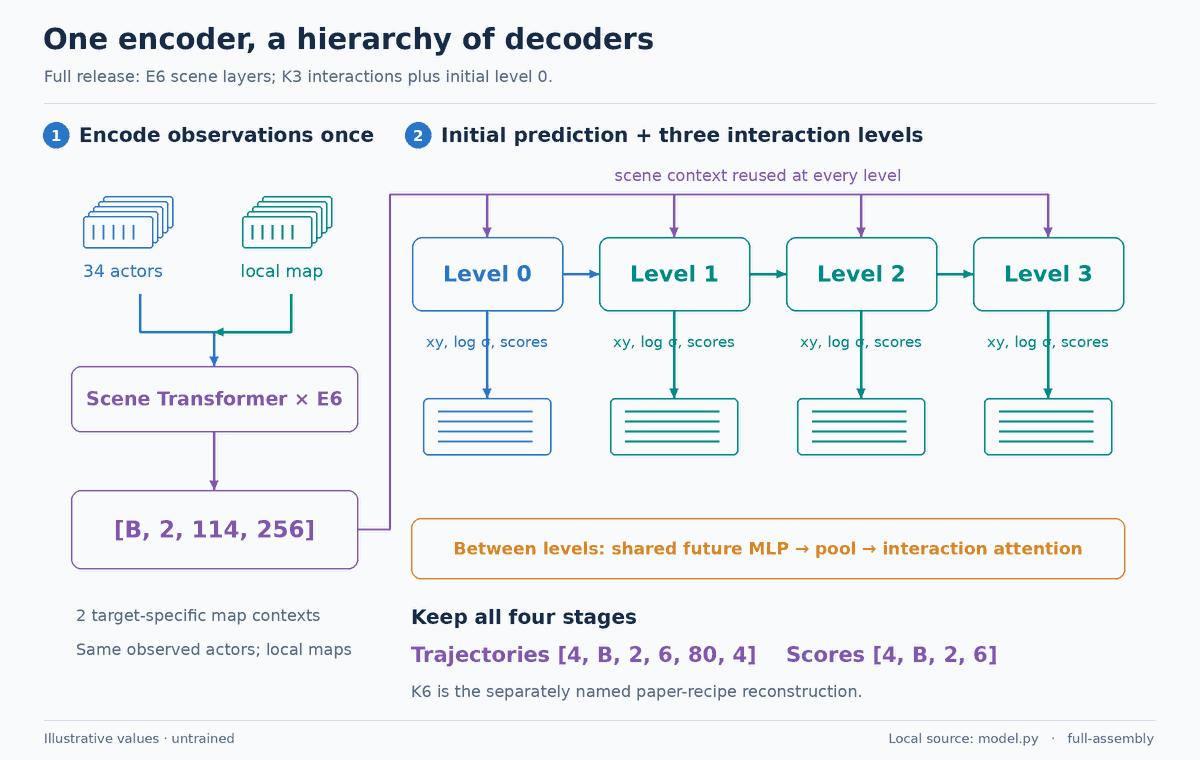

*Full release: E6 scene layers; K3 interactions plus initial level 0.*

In [ ]:
class GameFormer(nn.Module):
    def __init__(self, config: ModelConfig):
        super().__init__()
        self.config = c = config
        self.ego_encoder, self.agent_encoder = AgentEncoder(c.width), AgentEncoder(c.width)
        self.lane_encoder, self.crosswalk_encoder = LaneEncoder(c), CrosswalkEncoder(c.width)
        layer = nn.TransformerEncoderLayer(
            c.width, c.heads, c.width * 4, c.dropout, activation=F.gelu, batch_first=True
        )
        self.scene_encoder = nn.TransformerEncoder(
            layer, c.encoder_layers, enable_nested_tensor=False
        )
        self.mode_embedding = nn.Embedding(c.modes, c.width)
        self.agent_embedding = nn.Embedding(c.predicted, c.width)
        self.initial_cross, self.initial_head = AttentionBlock(c), GaussianHead(c)
        self.future_encoder = FutureEncoder(c)
        self.interactions = nn.ModuleList([InteractionDecoder(c) for _ in range(c.levels)])

    def forward(self, batch: dict[str, Tensor]) -> dict[str, Tensor]:
        c = self.config
        actors = torch.cat((batch["ego_state"][:, None], batch["neighbors_state"]), 1)
        actors = torch.where(batch["actor_valid"][..., None], actors, 0)
        b = actors.shape[0]
        actor_mask = ~batch["actor_valid"][..., -1]
        if actor_mask[:, 0].any():
            raise ValueError("Focal actor must be present")
        encoded_ego = self.ego_encoder(actors[:, 0])[:, None]
        if c.actors > 1:
            others = self.agent_encoder(actors[:, 1:].reshape(-1, c.history, 9)).reshape(
                b, c.actors - 1, c.width
            )
            encoded_actors = torch.cat((encoded_ego, others), 1)
        else:
            encoded_actors = encoded_ego
        lanes = torch.where(batch["lane_valid"][..., None], batch["map_lanes"], 0)
        crosswalks = torch.where(batch["crosswalk_valid"][..., None], batch["map_crosswalks"], 0)
        lane_features = self.lane_encoder(lanes).reshape(
            b * c.predicted, c.lanes, c.lane_points, c.width
        )
        cw_features = self.crosswalk_encoder(crosswalks).reshape(
            b * c.predicted, c.crosswalks, c.crosswalk_points, c.width
        )
        lane_tokens, lane_mask = segment_points(
            lane_features,
            batch["lane_valid"].reshape(b * c.predicted, c.lanes, c.lane_points),
            c.lane_stride,
            c.partial_segments,
        )
        cw_tokens, cw_mask = segment_points(
            cw_features,
            batch["crosswalk_valid"].reshape(b * c.predicted, c.crosswalks, c.crosswalk_points),
            c.crosswalk_stride,
            c.partial_segments,
        )
        scene = torch.cat(
            (
                encoded_actors[:, None]
                .expand(-1, c.predicted, -1, -1)
                .reshape(b * c.predicted, c.actors, c.width),
                lane_tokens,
                cw_tokens,
            ),
            1,
        )
        mask = torch.cat(
            (
                actor_mask[:, None].expand(-1, c.predicted, -1).reshape(b * c.predicted, c.actors),
                lane_mask,
                cw_mask,
            ),
            1,
        )
        scene = self.scene_encoder(scene, src_key_padding_mask=mask)
        scene = scene.reshape(b, c.predicted, -1, c.width)
        mask = mask.reshape(b, c.predicted, -1)
        focal_history = scene[
            :,
            torch.arange(c.predicted, device=actors.device),
            torch.arange(c.predicted, device=actors.device),
        ]
        query = (
            focal_history[:, :, None]
            + self.mode_embedding.weight[None, None]
            + self.agent_embedding.weight[None, :, None]
        )
        content = self.initial_cross(
            query.reshape(b * c.predicted, c.modes, c.width),
            scene.reshape(b * c.predicted, -1, c.width),
            mask.reshape(b * c.predicted, -1),
        ).reshape(b, c.predicted, c.modes, c.width)
        current = actors[:, : c.predicted, -1]
        trajectories, scores = self.initial_head(content, current)
        all_trajectories, all_scores = [trajectories], [scores]
        for module in self.interactions:
            block = cast(InteractionDecoder, module)
            multi = self.future_encoder(trajectories[..., :2], current)
            weighted = multi * scores.softmax(-1)[..., None]
            futures = weighted.sum(2) if c.normalized_future_pool else weighted.mean(2)
            interaction = block.interaction(futures, futures, actor_mask[:, : c.predicted])
            context = torch.cat((interaction[:, None].expand(-1, c.predicted, -1, -1), scene), 2)
            future_mask = actor_mask[:, None, : c.predicted].expand(-1, c.predicted, -1).clone()
            future_mask |= torch.eye(c.predicted, device=actors.device, dtype=torch.bool)[None]
            combined_mask = torch.cat((future_mask, mask), 2)
            content = block.cross(
                (content + multi).reshape(b * c.predicted, c.modes, c.width),
                context.reshape(b * c.predicted, -1, c.width),
                combined_mask.reshape(b * c.predicted, -1),
            ).reshape(b, c.predicted, c.modes, c.width)
            trajectories, scores = block.head(content, current)
            all_trajectories.append(trajectories)
            all_scores.append(scores)
        return {"trajectories": torch.stack(all_trajectories), "scores": torch.stack(all_scores)}

In [ ]:
model = GameFormer(config)
outputs = model(batch)
assert outputs["trajectories"].shape == (2, 2, 2, 6, 80, 4)
print("Parameters:", sum(p.numel() for p in model.parameters()))

## Actual training objectives

Select one shared joint mode by its displacement errors. For the joint predictor, use the temporal mean and 3/5/8-second horizons. The diagonal NLL, up to an additive constant, is $log\sigma_x+log\sigma_y+\frac12[(d_x/\sigma_x)^2+(d_y/\sigma_y)^2]$. The printed Eq. 3 repeats x; the correct y term agrees with the released code. Add twice the joint score cross-entropy with label smoothing .2. Sum all levels. Missing labels contribute neither error nor denominator.

Planning uses its released imitation reduction and adds .1 times the cross-level potential at levels k≥1. The potential is 1/(distance+1) below 3 m. It compares ego to previous neighbors, and neighbors to previous other neighbors, matching the released directional objective. The supplement intentionally omits this penalty for joint prediction.

### Choose a whole scene alternative, then teach its coordinates and score

Training first selects one *joint winner*, using both agents' valid trajectory
errors. In the toy comparison, errors `(0,10)` average to 5 for mode 0, whereas
`(2,2)` average to 2 for mode 1. Assume all 80 labels are valid and each error
is constant across time, including horizon indices 29, 49 and 79. Then
adding the three horizon errors makes joint costs 20 and 8, preserving mode 1
for both agents. Independently choosing each agent's nearest path would create
a different objective. The full selector combines temporal mean displacement
with 3-, 5- and 8-second errors (indices 29,49,79), then averages available
agents. This discrete choice does not differentiate through the winning index.

For the chosen Gaussian, residual `(2,0)` with both sigmas 1 gives NLL=2,
omitting the constant Gaussian term as the code does. If every valid timestep
has those values, temporal mean 2 plus three horizon terms gives regression
8. This assumption is needed for the displayed arithmetic. Joint log-sigmas
are clamped to `[0,5]`; scores receive twice the summed-agent cross-entropy
with label smoothing .2. Validity controls reductions, and every level adds
its own loss.

Planning changes reductions and adds .1 potential after level 0. At distance
1 m its potential is .5; at 3 m the strict threshold gives zero. It finds the
nearest previous neighbor across modes, uses the released directional pairs,
and does not detach previous predictions in this loss. The probe checks finite
joint components; the additional analytical probe checks regression 8 and the
winning mode's gradient path. These checks establish no official score or
planning safety guarantee.

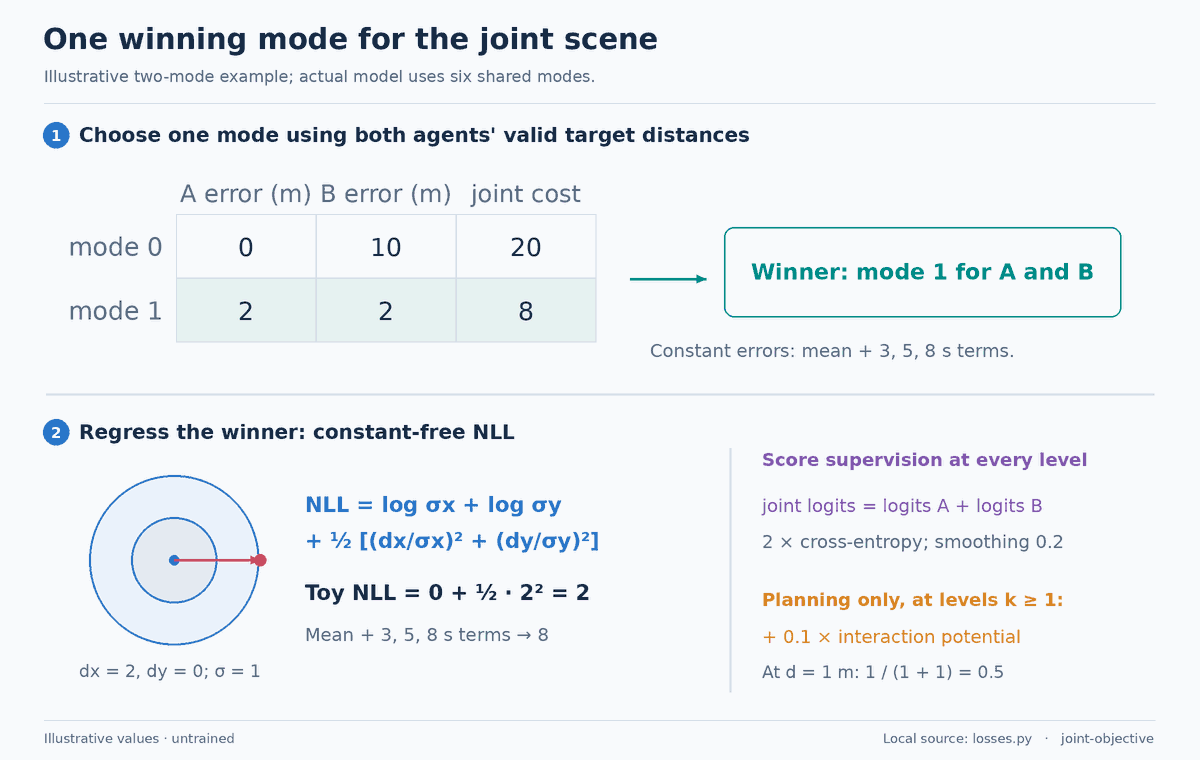

*Illustrative two-mode example; actual model uses six shared modes.*

In [ ]:
def masked_mean(value: Tensor, valid: Tensor) -> Tensor:
    return torch.where(valid, value, 0).sum() / valid.sum().clamp_min(1)


def interaction_potential(current: Tensor, previous: Tensor, valid: Tensor) -> Tensor:
    """B,P,M,T,2. Ego->previous neighbors; neighbors->previous other neighbors."""
    b, n, m, t, _ = current.shape
    if n < 2:
        return current.sum() * 0
    prev = previous[:, 1:].permute(0, 3, 1, 2, 4).reshape(b * t, (n - 1) * m, 2)
    others_valid = (
        valid[:, 1:].permute(0, 2, 1)[..., None].expand(-1, -1, -1, m).reshape(b * t, (n - 1) * m)
    )
    ego = current[:, 0].permute(0, 2, 1, 3).reshape(b * t, m, 2)
    distance = torch.cdist(ego, prev).masked_fill(~others_valid[:, None], 1000).amin(-1)
    ego_valid = valid[:, 0].reshape(b * t, 1)
    potential = torch.where((distance < 3) & ego_valid, 1 / (distance + 1), 0)
    ego_loss = potential.reshape(b, t, m).sum((1, 2)).mean()
    neighbors = current[:, 1:].permute(0, 3, 1, 2, 4).reshape(b * t, (n - 1) * m, 2)
    distance = torch.cdist(neighbors, prev)
    same_agent = (
        torch.eye(n - 1, dtype=torch.bool, device=current.device)
        .repeat_interleave(m, 0)
        .repeat_interleave(m, 1)
    )
    pair_mask = (~others_valid[:, None]) | same_agent[None]
    distance = distance.masked_fill(pair_mask, 1000).amin(-1)
    potential = torch.where((distance < 3) & others_valid, 1 / (distance + 1), 0)
    # Match source's time sum and mean across current neighbor-mode entries.
    denominator = valid[:, 1:].any(-1).sum(-1).clamp_min(1) * m
    neighbor_loss = (potential.reshape(b, t, -1).sum((1, 2)) / denominator).mean()
    return ego_loss + neighbor_loss


def objective(outputs: dict[str, Tensor], batch: dict[str, Tensor], task: str) -> dict[str, Tensor]:
    if task not in ("joint", "planning"):
        raise ValueError("task must be joint or planning")
    valid = batch["future_valid"]
    target = torch.where(valid[..., None], batch["future"].float(), 0)
    stages = outputs["trajectories"].float()
    logits = outputs["scores"].float()
    valid_agents = valid.any(-1)
    valid_scenes = valid_agents.any(-1)
    zero = stages.sum() * 0 + logits.sum() * 0
    regression, classification, interaction = zero, zero, zero
    for level, raw in enumerate(stages):
        clean = torch.where(valid[:, :, None, :, None], raw, 0)
        distance = (clean[..., :2] - target[:, :, None]).norm(dim=-1)
        if task == "joint":
            if target.shape[1:3] != (2, 80):
                raise ValueError("Joint objective requires two agents and 80 future samples")
            temporal = (distance * valid[:, :, None]).sum(-1) / valid.sum(-1)[:, :, None].clamp_min(
                1
            )
            horizons = torch.tensor([29, 49, 79], device=target.device)
            temporal = temporal + (distance[..., horizons] * valid[:, :, None, horizons]).sum(-1)
        else:
            sampled = valid[..., 4::5]
            temporal = (distance[..., 4::5] * sampled[:, :, None]).sum(-1) / sampled.sum(-1)[
                :, :, None
            ].clamp_min(1)
        joint_distance = (temporal * valid_agents[..., None]).sum(1) / valid_agents.sum(1)[
            :, None
        ].clamp_min(1)
        mode = joint_distance.argmin(-1)
        b, p, _, t, _ = raw.shape
        chosen = clean.gather(2, mode[:, None, None, None, None].expand(b, p, 1, t, 4)).squeeze(2)
        dx = target - chosen[..., :2]
        lo, hi = (0, 5) if task == "joint" else (-2, 2)
        log_std = chosen[..., 2:].clamp(lo, hi)
        nll = log_std.sum(-1) + 0.5 * (dx * torch.exp(-log_std)).square().sum(-1)
        nll = torch.where(valid, nll, 0)
        if task == "joint":
            per_agent = nll.sum(-1) / valid.sum(-1).clamp_min(1) + nll[..., horizons].sum(-1)
            regression = regression + masked_mean(per_agent, valid_agents)
            scene_logits = (logits[level] * valid_agents[..., None]).sum(1)
            ce = F.cross_entropy(scene_logits, mode, label_smoothing=0.2, reduction="none")
            classification = classification + 2 * masked_mean(ce, valid_scenes)
        else:
            regression = regression + masked_mean(nll, valid) + masked_mean(nll[:, 0], valid[:, 0])
            ce = F.cross_entropy(
                logits[level].transpose(1, 2),
                mode[:, None].expand(-1, p),
                label_smoothing=0.2,
                reduction="none",
            )
            classification = classification + masked_mean(ce, valid_agents)
            if level:
                interaction = interaction + 0.1 * interaction_potential(
                    clean[..., :2],
                    torch.where(valid[:, :, None, :, None], stages[level - 1, ..., :2], 0),
                    valid,
                )
    return {
        "loss": regression + classification + interaction,
        "regression": regression,
        "classification": classification,
        "interaction": interaction,
    }

In [ ]:
components = objective(outputs, batch, "joint")
assert torch.isfinite(components["loss"])
print({name: float(value.detach()) for name, value in components.items()})

In [ ]:
# The figure's distances are constant over all 80 valid timesteps.
toy_prediction = torch.zeros(1, 1, 2, 2, 80, 4)
toy_prediction[0, 0, 1, 0, :, 0] = 10  # mode 0 fits only the first agent
toy_prediction[0, 0, :, 1, :, 0] = 2  # mode 1 fits both agents
toy_prediction.requires_grad_()
toy_targets = {
    "future": torch.zeros(1, 2, 80, 2),
    "future_valid": torch.ones(1, 2, 80, dtype=torch.bool),
}
toy_loss = objective(
    {"trajectories": toy_prediction, "scores": torch.zeros(1, 1, 2, 2)}, toy_targets, "joint"
)
torch.testing.assert_close(toy_loss["regression"], torch.tensor(8.0))
toy_loss["regression"].backward()
assert toy_prediction.grad[0, 0, :, 0].count_nonzero() == 0
assert toy_prediction.grad[0, 0, :, 1, :, :2].count_nonzero() > 0
# Probe uncertainty learning inside the clamp range, away from its boundary.
interior_prediction = toy_prediction.detach().clone()
interior_prediction[..., 2:] = 0.5
interior_prediction.requires_grad_()
interior_loss = objective(
    {"trajectories": interior_prediction, "scores": torch.zeros(1, 1, 2, 2)}, toy_targets, "joint"
)
torch.testing.assert_close(interior_loss["regression"], torch.tensor(4 * (1 + 2 / math.e)))
interior_loss["regression"].backward()
assert interior_prediction.grad[0, 0, :, 1, :, 2:].count_nonzero() > 0
print("Joint winner: mode 1; regression = 8; only its Gaussian gets regression gradients.")

## Backward and one real optimizer update

Losses are computed in FP32. The following cell performs the actual objective, backward pass, gradient clipping and AdamW update. Optimizer state and randomness must later be saved for faithful recovery. The teaching example uses one CPU batch; the trainer also supports sample-weighted accumulation and mixed precision.

### Trace one update all the way to changed parameters

Forward computes predictions and loss; backward applies the chain rule to
compute parameter gradients; the optimizer uses those gradients to change
weights. A gradient is a local sensitivity, not a prediction error with the
same units. In the toy scalar loss $L=\frac12w^2$ at w=2, the gradient is 2.
For the first AdamW step with learning rate .1, zero weight decay and epsilon
ignored, bias-corrected moments are 2 and 4. The update is
$.1\cdot2/\sqrt4=.1$, giving w=1.9. Those assumptions explain why the drawing
is simple; the actual notebook optimizer has different hyperparameters.

The real probe clears gradients, rebuilds a forward graph, backpropagates the
actual joint objective, clips the total gradient norm at 5, and steps AdamW.
The returned norm is measured before clipping, so it may exceed 5. With
mixed precision, unscale gradients before clipping; Gaussian loss arithmetic
is converted to FP32. The trainer also weights accumulated microbatches by
their actual sample counts: sizes 2 and 1 contribute 2/3 and 1/3, rather than
equal halves. This preserves its sample-weighted update convention for a
partial final group. One finite synthetic update establishes execution, not
convergence or reproduction of the paper's training recipe.

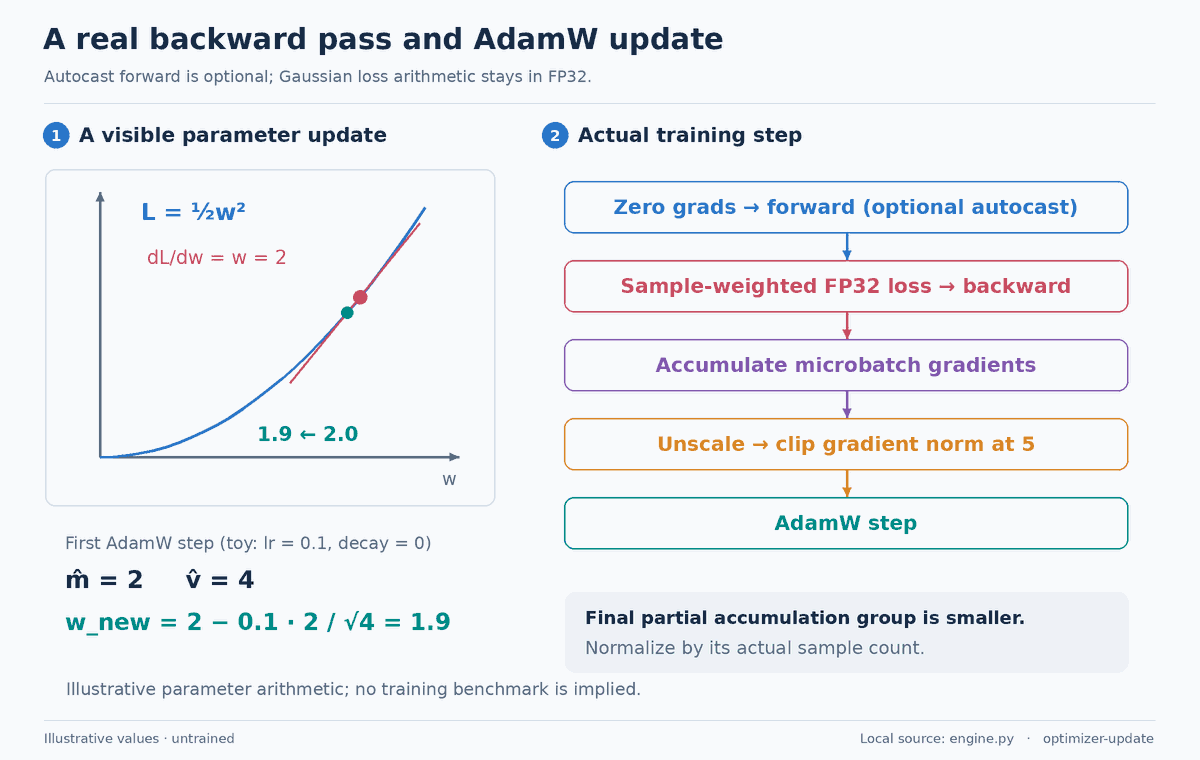

*Autocast forward is optional; Gaussian loss arithmetic stays in FP32.*

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
optimizer.zero_grad(set_to_none=True)
loss = objective(model(batch), batch, "joint")["loss"]
loss.backward()
gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
optimizer.step()
assert torch.isfinite(gradient_norm)
print("Gradient norm:", float(gradient_norm))

## Decode and measure

Sum agent logits, softmax over modes, and select the same highest-score mode for every agent. Diagnostic ADE is average valid displacement; FDE uses each agent’s last valid step. Official WOMD metrics require the SDK, actual labels and the prescribed split. The adapter below requires full labeled states and explicit validity; it cannot produce official results merely by renaming a diagnostic.

### Let scores select first; consult labels only to measure afterward

Inference uses the final level. Sum both agents' scores for each joint mode,
softmax across modes and choose a common winner. For summed logits
`(0,log(8),0)`, probabilities are `(.1,.8,.1)` and mode 1 supplies both
agents' paths. Selection never sees future labels. A nearest-to-label choice
would instead be an oracle comparison and answer a different question.
The planning diagnostic follows the released helper's per-agent argmax, so
its selection rule is deliberately different.

ADE is mean displacement over valid steps; FDE is displacement at each
agent's last valid step. For valid errors `(1,2,3)` m, ADE is 2 m and FDE is
3 m. An additional padded error 99 m changes neither. Aggregate sums and valid counts across
batches before dividing; padding must contribute neither error nor count.

The official joint adapter keeps all six hypotheses and subsamples future
indices `4,9,...,79`, corresponding to 0.5-second intervals, to form
`[B,1,6,2,16,2]`. Its singleton axis groups both agents as one joint prediction.
The probe checks this layout and plots selected synthetic paths. Official
WOMD metrics additionally require genuine state labels, compatible SDK and
the prescribed split; a shape-correct adapter and random-model plot establish
none of those results.

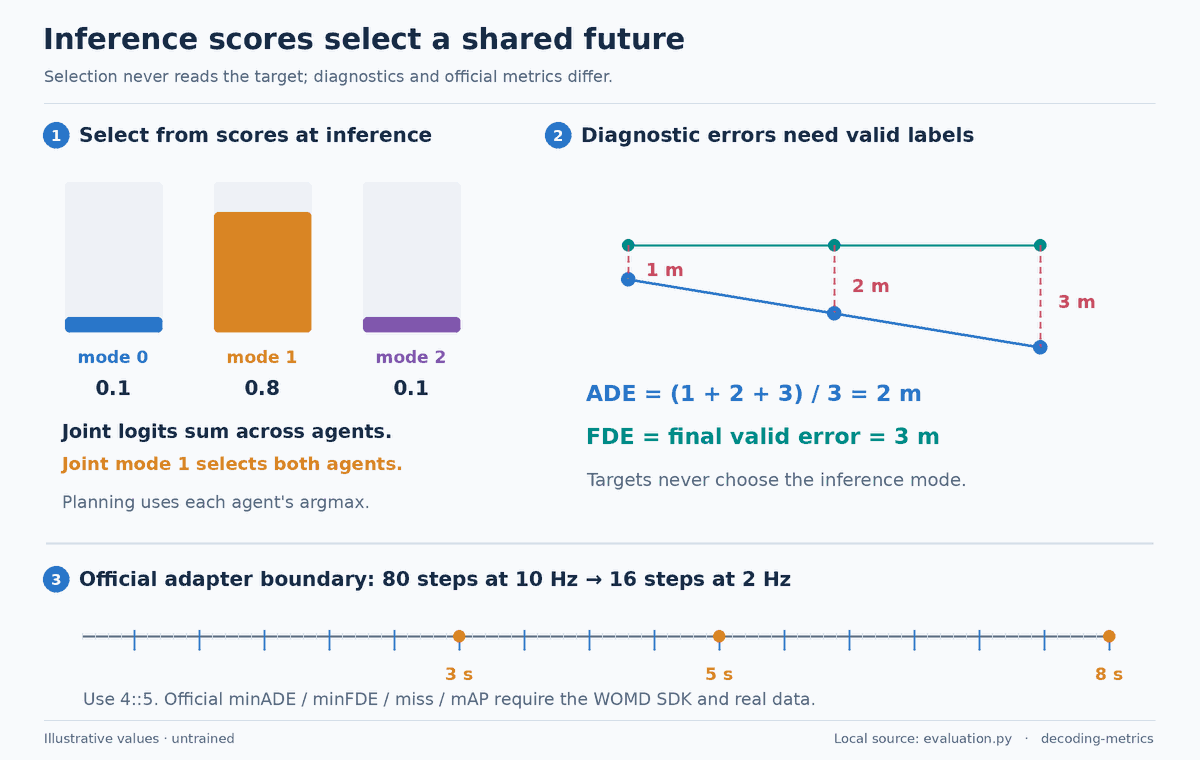

*Selection never reads the target; diagnostics and official metrics differ.*

In [ ]:
def decode(outputs: dict[str, Tensor], task: str = "joint") -> tuple[Tensor, Tensor]:
    trajectories, scores = outputs["trajectories"][-1], outputs["scores"][-1]
    b, p, _, t, _ = trajectories.shape
    if task == "joint":
        probabilities = scores.sum(1).softmax(-1)
        mode = probabilities.argmax(-1)[:, None].expand(-1, p)
    elif task == "planning":
        probabilities = scores.softmax(-1)
        mode = probabilities.argmax(-1)
    else:
        raise ValueError("task must be joint or planning")
    selected = trajectories.gather(2, mode[:, :, None, None, None].expand(b, p, 1, t, 4)).squeeze(2)
    return selected[..., :2], probabilities


def diagnostic_totals(
    outputs: dict[str, Tensor], batch: dict[str, Tensor], task: str = "joint"
) -> dict[str, float]:
    prediction, _ = decode(outputs, task)
    valid = batch["future_valid"]
    target = torch.where(valid[..., None], batch["future"], 0)
    distance = (prediction.float() - target).norm(dim=-1)
    steps = torch.arange(valid.shape[-1], device=valid.device)
    last = torch.where(valid, steps, -1).amax(-1)
    present = last >= 0
    final = distance.gather(-1, last.clamp_min(0)[..., None]).squeeze(-1)
    return {
        "distance_sum": float(torch.where(valid, distance, 0).sum()),
        "valid_steps": float(valid.sum()),
        "final_distance_sum": float(torch.where(present, final, 0).sum()),
        "valid_agents": float(present.sum()),
    }


def official_metric_inputs(
    outputs: dict[str, Tensor], batch: dict[str, Tensor]
) -> dict[str, Tensor]:
    """WOMD joint layout: B,1,M,2,16,2; actual labeled state/validity required."""
    future = batch["future_state"]
    if future.shape[1:3] != (2, 80):
        raise ValueError("Official joint metrics require two agents and 80 future steps")
    actors = torch.cat((batch["ego_state"][:, None], batch["neighbors_state"]), 1)[:, :2]
    all_state = torch.cat((actors[..., :5], future), 2)
    sizes = actors[:, :, -1, 5:7][:, :, None].expand(-1, -1, all_state.shape[2], -1)
    gt = torch.cat((all_state[..., :2], sizes, all_state[..., 2:]), -1)
    probabilities = outputs["scores"][-1].sum(1).softmax(-1)
    b = future.shape[0]
    return {
        "prediction_trajectory": outputs["trajectories"][-1, ..., 4::5, :2].permute(0, 2, 1, 3, 4)[
            :, None
        ],
        "prediction_score": probabilities[:, None],
        "ground_truth_trajectory": gt,
        "ground_truth_is_valid": torch.cat(
            (batch["actor_valid"][:, :2], batch["future_valid"]), -1
        ),
        "object_type": actors[:, :, -1, 8].long(),
        "prediction_ground_truth_indices": torch.arange(2, device=future.device)[None, None].expand(
            b, 1, -1
        ),
        "prediction_ground_truth_indices_mask": batch["future_valid"].any(-1)[:, None],
    }


def official_metrics(inputs: dict[str, Tensor]) -> dict[str, float]:
    try:
        import tensorflow as tf
        from google.protobuf import text_format
        from waymo_open_dataset.metrics.ops import py_metrics_ops
        from waymo_open_dataset.metrics.python import config_util_py
        from waymo_open_dataset.protos import motion_metrics_pb2
    except ImportError as error:
        raise RuntimeError(
            "Official evaluation requires the compatible Waymo/TensorFlow SDK; see docs/data.md"
        ) from error
    config = motion_metrics_pb2.MotionMetricsConfig()
    text_format.Parse(
        """track_steps_per_second:10 prediction_steps_per_second:2
    track_history_samples:10 track_future_samples:80 speed_lower_bound:1.4
    speed_upper_bound:11.0 speed_scale_lower:0.5 speed_scale_upper:1.0
    step_configurations {measurement_step:5 lateral_miss_threshold:1.0 longitudinal_miss_threshold:2.0}
    step_configurations {measurement_step:9 lateral_miss_threshold:1.8 longitudinal_miss_threshold:3.6}
    step_configurations {measurement_step:15 lateral_miss_threshold:3.0 longitudinal_miss_threshold:6.0}
    max_predictions:6""",
        config,
    )
    values = py_metrics_ops.motion_metrics(
        config=config.SerializeToString(),
        **{
            name: tf.convert_to_tensor(value.detach().cpu().numpy())
            for name, value in inputs.items()
        },
    )
    breakdowns = config_util_py.get_breakdown_names_from_motion_config(config)
    return {
        f"official/{metric}/{name}": float(values[i][j].numpy())
        for i, metric in enumerate(("minADE", "minFDE", "miss_rate", "overlap_rate", "mAP"))
        for j, name in enumerate(breakdowns)
    }

In [ ]:
model.eval()
with torch.no_grad():
    inference = model(batch)
selected, probabilities = decode(inference)
print("Selected xy:", selected.shape)
print(diagnostic_totals(inference, batch))
sdk_layout = official_metric_inputs(inference, batch)
assert sdk_layout["prediction_trajectory"].shape == (2, 1, 6, 2, 16, 2)
fig, ax = plt.subplots(figsize=(6, 3))
for agent in range(2):
    truth = batch["future"][0, agent]
    path = selected[0, agent]
    ax.plot(truth[:, 0], truth[:, 1], "--", label=f"target {agent}")
    ax.plot(path[:, 0], path[:, 1], label=f"random-model prediction {agent}")
ax.set(xlabel="local x (m)", ylabel="local y (m)", title="Synthetic diagnostic after one update")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
plt.close(fig)

## Optional real data and recovery

Infrastructure is separate from the model. `gameformer.engine` provides data loading, atomic epoch-boundary checkpoints and tracking. These imports are deliberately opt-in; the architecture above needs no package import. Read the data guide for practical-preprocessing differences. Explicit real mode fails if assets are missing. A full training run requires a dataset, hardware preflight and an authorized budget. Schema-2 checkpoints keep the sampler independent of worker startup and reject changed cache manifests before restoring state. Original config/environment records remain intact; `sessions/` stores every restart. Exact recovery covers deterministic datasets without random worker augmentation.

### Recovery needs the training state and the data identity

Weights alone cannot reproduce the next training update. AdamW retains
gradient moments, the scheduler retains learning-rate progress, mixed
precision may retain scaler state, and random generators determine dropout
and sample order. Save them with the completed epoch, timing state and run
identity. A temporary file is flushed and synced before atomic replacement,
so an interrupted write does not expose a half-written latest checkpoint.

At an epoch boundary, completing epoch 6 means the next run continues with
epoch 7; it does not replay an arbitrary fraction of epoch 6. The independent
sampler generator matters because worker startup consumes randomness too:
restarting workers must not advance the future shuffle order. Schema 2 also
checks cache manifests before restoring state and preserves original records
alongside restart-specific sessions.

These guarantees cover deterministic datasets without random worker
augmentation; they do not promise mid-epoch recovery. The following opt-in
cell stays disabled by default and requires genuine prepared caches when
enabled. It is an entry point for a separately budgeted run, not a notebook
recovery experiment. The default local architecture still runs offline without
importing the training infrastructure.

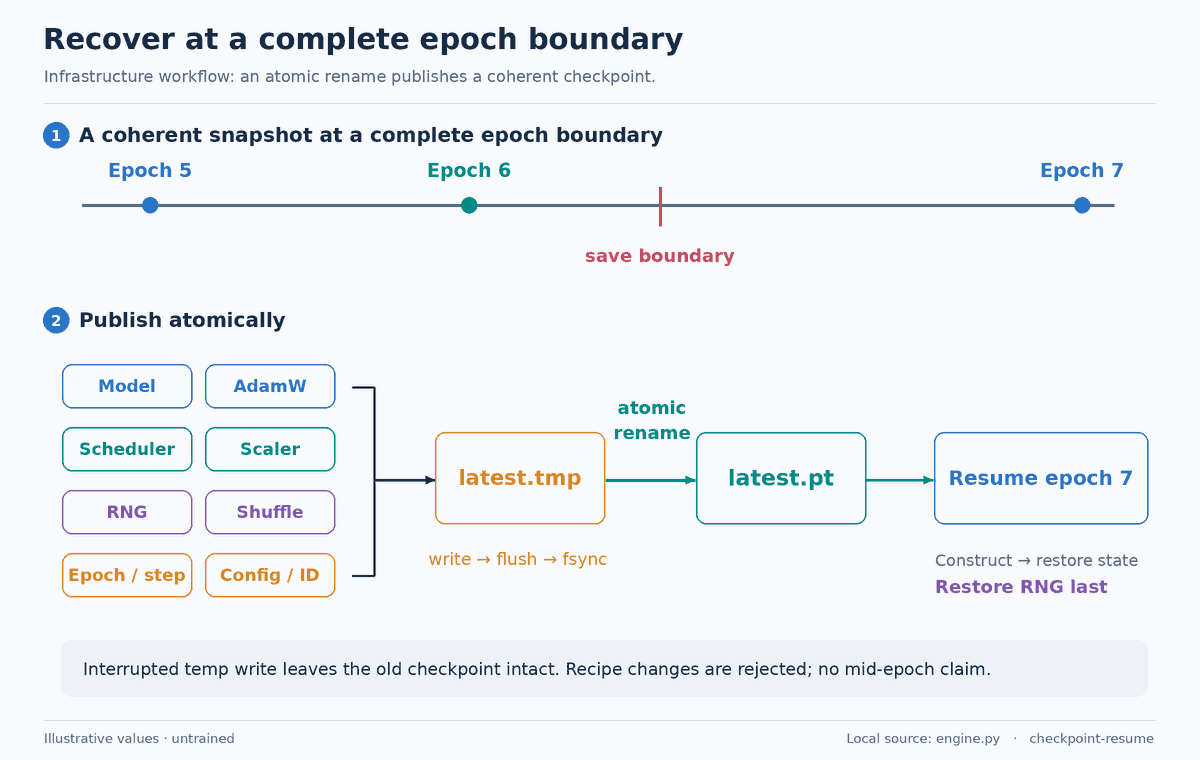

*Infrastructure workflow: an atomic rename publishes a coherent checkpoint.*

In [ ]:
RUN_REAL = False
if RUN_REAL:
    from pathlib import Path

    from gameformer.config import RunConfig
    from gameformer.engine import train

    real_config = RunConfig.load("configs/practical_joint.json")
    if not real_config.train_data or not Path(real_config.train_data).is_dir():
        raise FileNotFoundError("Set train_data and validation_data to genuine prepared caches")
    train(real_config, "outputs/real-run")

## Tracking and trustworthy remaining time

MLflow is optional and logs the experiment’s source/config/data identity, loss components, gradient norms, trajectories and progress. After resume, measure the current session’s rate and estimate only remaining work. Include observed validation and checkpoint overhead; report active time separately from wall time and downtime. Estimates before two completed epochs are provisional. `progress.json` works with tracking disabled.

### A remaining-time estimate is a measurement of the current session

After a restart, distinguish work already completed from speed observed now.
Suppose 6 of 10 epochs are complete, and this session completed 2 in 20
seconds. Its rate is .1 epoch/second, so four remaining epochs suggest
$4/.1=40$ seconds. If prior sessions accumulated 40 active seconds, total
active time is 60 seconds. A wall clock spanning 100 seconds also includes
40 seconds when training was inactive. Folding that downtime into throughput
would misdescribe the current session's speed.

An epoch's measured duration includes observed validation and checkpoint
overhead, so the estimate describes the actual loop rather than only model
steps. It still assumes future epochs resemble the measured ones; hardware
load or evaluation changes can break that assumption. Before two completed
session epochs, the displayed estimate is marked provisional. With no usable
rate yet, remaining time is unknown rather than an invented number.

The probe verifies the toy 40-second arithmetic. The trainer writes
`progress.json` even without MLflow; optional tracking displays active time,
wall time, progress and timezone-aware expected finish. Such metadata makes
compute use inspectable, while providing no evidence that prediction quality
has improved.

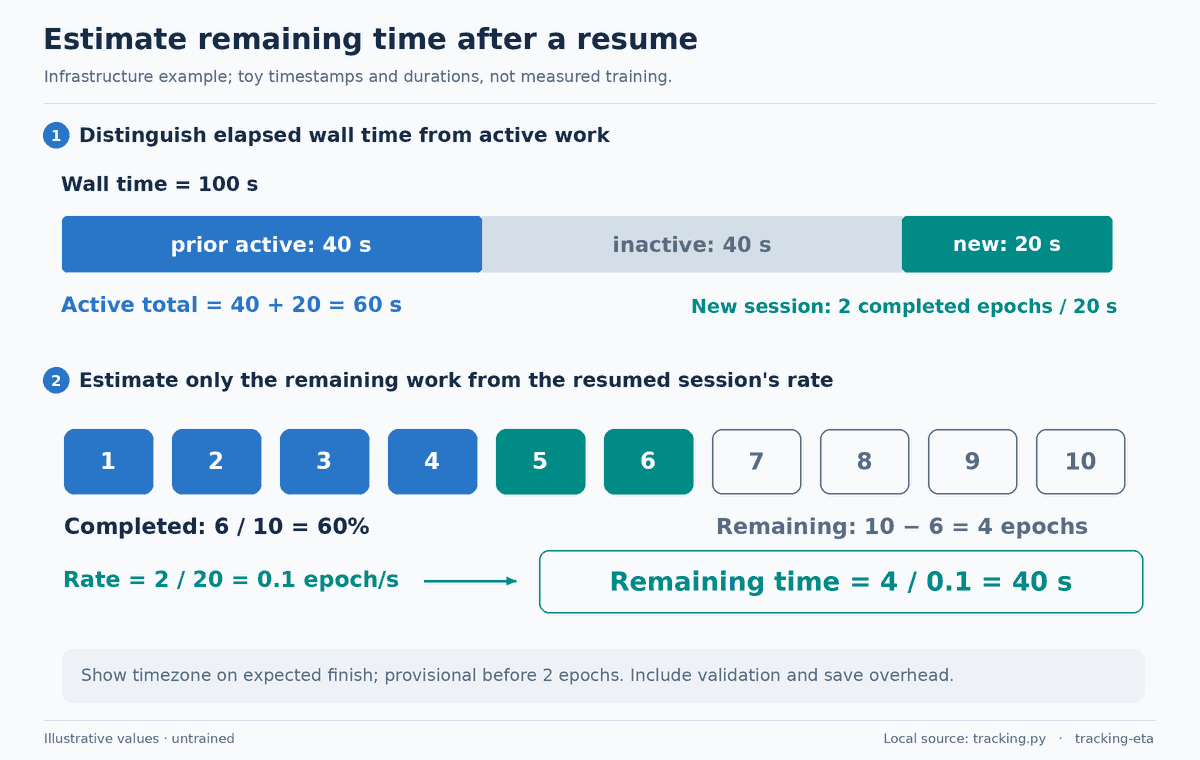

*Infrastructure example; toy timestamps and durations, not measured training.*

In [ ]:
completed, total = 6, 10
session_epochs, session_seconds = 2, 20
remaining_seconds = (total - completed) / (session_epochs / session_seconds)
assert remaining_seconds == 40
print("Toy remaining duration:", remaining_seconds, "seconds")

## What this execution establishes

The model, actual objectives and optimizer update execute on seeded synthetic CPU data. It establishes no paper metric, real-data parity or closed-loop planning score. The release omits the 64-mode EM ensemble and closed-loop WOMD code; nuPlan adds a distinct planning framework. The source audit records these boundaries and the corrected validity behavior. Refer to `COMMAND_GUIDE.md` for training, resume, local MLflow, loader/step/end-to-end benchmarks and bounded tuning.